<a href="https://colab.research.google.com/github/rafaalathais/analise-gasto-parlamentar/blob/main/notebook_gasto_parlamentar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gastos da CEAPS dos senadores
**Disciplina**: IMD1151 - Ciências de Dados

**Grupo**:
*   Gabriel Ferreira Cavalcante
*   Jordson Albino Galvão Tavares
*   Rafaela Thais de Abreu Lúcio Maia

## Introdução

Este projeto tem como objetivo realizar uma Análise Exploratória de Dados sobre os gastos da Cota para o Exercício da Atividade Parlamentar dos Senadores (CEAPS), buscando identificar padrões, tendências e diferenças na utilização dos recursos públicos destinados à atividade parlamentar.

Nesta etapa, analisamos os anos completos de 2008 a 2025. Os dados de 2026 ficam para uma análise separada.

### Objetivo

Serão realizadas a obtenção dos registros históricos, a identificação das variáveis disponíveis e a verificação inicial de problemas como dados ausentes, inconsistências e diferenças de estrutura entre os arquivos.

Os dados consolidados servirão de base para as etapas posteriores de limpeza, transformação e análise exploratória.

## Perguntas de pesquisa

O projeto busca responder às seguintes perguntas:

- Em quais períodos do ano os senadores apresentam maiores gastos? Como essas despesas evoluíram ao longo dos anos?

- Quais unidades federativas apresentam os maiores gastos associados aos seus senadores?

- Quais partidos apresentam os maiores gastos totais e médios, tanto nacionalmente quanto por unidade federativa?

- Quais senadores apresentam os maiores gastos da cota parlamentar?

- Quais tipos de despesas representam a maior parcela dos gastos parlamentares?

Como possível extensão do projeto, pretende-se investigar a identificação de perfis de senadores com base em seus padrões de despesas.

## Fontes de dados

Os dados serão obtidos por meio do Portal de Dados Abertos do Senado Federal.


## Coleta da CEAPS

A CEAPS está no [Portal de Dados Abertos do Senado](https://www12.senado.leg.br/dados-abertos/administrativo/senadores/cotas-para-exercicio-da-atividade-parlamentar). A API administrativa oferece um CSV por ano em `https://adm.senado.gov.br/adm-dadosabertos/api/v1/senadores/despesas_ceaps/{ano}/csv`.

Os CSVs de 2008 a 2025 ficam, sem alterações, em `dados_cache/`. O notebook reutiliza esses arquivos nas próximas execuções. A tabela de coleta mostra o resultado de cada ano. Se algum ano falhar, o notebook interrompe a preparação. Assim, uma coleta parcial não é tratada como completa.

In [1]:
from io import BytesIO
from pathlib import Path
import time
import unicodedata

import pandas as pd
import requests
from IPython.display import Markdown, display

ANOS = list(range(2008, 2026))
URL_CEAPS = 'https://adm.senado.gov.br/adm-dadosabertos/api/v1/senadores/despesas_ceaps/{}/csv'
CACHE = Path('dados_cache')
CACHE.mkdir(exist_ok=True)

def obter_csv(ano):
    caminho = CACHE / f'ceaps_{ano}.csv'
    if caminho.is_file() and caminho.stat().st_size > 0:
        return caminho.read_bytes(), 'cache'
    ultimo_erro = None
    for tentativa in range(3):
        try:
            resposta = requests.get(URL_CEAPS.format(ano), timeout=(15, 90))
            resposta.raise_for_status()
            if not resposta.content:
                raise ValueError('resposta vazia')
            return resposta.content, 'download'
        except (requests.RequestException, ValueError) as erro:
            ultimo_erro = erro
            if tentativa < 2:
                time.sleep(2 ** tentativa)
    raise RuntimeError(f'ano {ano}: {ultimo_erro}')


In [2]:
dfs_despesas = {}
estado_coleta = []
colunas_essenciais = {'ID', 'ANO', 'MÊS', 'COD_SENADOR', 'VALOR_REEMBOLSADO'}

for ano in ANOS:
    try:
        conteudo, origem = obter_csv(ano)
        quadro = pd.read_csv(BytesIO(conteudo), sep=';', dtype='string', encoding='utf-8-sig')
        if quadro.empty or not colunas_essenciais.issubset(quadro.columns):
            raise ValueError('CSV vazio ou sem as colunas essenciais')
        dfs_despesas[ano] = quadro
        if origem == 'download':
            (CACHE / f'ceaps_{ano}.csv').write_bytes(conteudo)
        estado_coleta.append({'ano': ano, 'origem': origem, 'registros': len(quadro), 'erro': ''})
    except Exception as erro:
        estado_coleta.append({'ano': ano, 'origem': 'falha', 'registros': 0, 'erro': str(erro)})

tabela_coleta = pd.DataFrame(estado_coleta)
display(tabela_coleta)
anos_falhos = tabela_coleta.loc[tabela_coleta.origem.eq('falha'), 'ano'].tolist()
if anos_falhos:
    raise RuntimeError(f'Coleta CEAPS incompleta. Anos com falha: {anos_falhos}.')


,ano,origem,registros,erro
0,2008,cache,2449,
1,2009,cache,16480,
2,2010,cache,18235,
3,2011,cache,25574,
4,2012,cache,30175,
5,2013,cache,29376,
6,2014,cache,22002,
7,2015,cache,26055,
8,2016,cache,26768,
9,2017,cache,27023,


In [3]:
display(dfs_despesas[2025].head(5))


,ID,TIPO_DOCUMENTO,ANO,MÊS,COD_SENADOR,NOME_SENADOR,TIPO_DESPESA,CPF_CNPJ_FORNECEDOR,NOME_FORNECEDOR,DOCUMENTO,DATA,DETALHAMENTO,VALOR_REEMBOLSADO
0,2250668,Nota Fiscal Eletrônica,2025,2,5672,ALAN RICK,"Locomoção, hospedagem, alimentação, combustíve...",06.906.483/0001-74,POSTO VILLAGE LTDA,73594,2025-03-06,<NA>,"5130,07"
1,2249896,Nota Fiscal Eletrônica,2025,2,5672,ALAN RICK,"Locomoção, hospedagem, alimentação, combustíve...",07.454.351/0001-11,QUILIMANJARO COMDE ALIMHOTELLTDA,179158,2025-02-22,<NA>,"83,80"
2,2253644,Fatura,2025,3,5672,ALAN RICK,"Aluguel de imóveis para escritório político, c...",66.970.229/0132-26,CLARO NXT TELECOMUNICAÇÕES S.A,733127,2025-03-18,<NA>,"418,01"
3,2253646,Recibo,2025,3,5672,ALAN RICK,"Aluguel de imóveis para escritório político, c...",860.***.***-53,LARISSA MAIA MARTINELLO,03/2025,2025-03-25,<NA>,"4000,00"
4,2252906,Fatura,2025,3,5672,ALAN RICK,"Contratação de consultorias, assessorias, pesq...",05.120.923/0001-09,AEROTUR SERVIÇOS,2223234094,2025-03-11,<NA>,"1469,95"


In [4]:
colunas_referencia = set(dfs_despesas[ANOS[0]].columns)
tabela_estrutura = pd.DataFrame([{
    'ano': ano,
    'colunas': len(quadro.columns),
    'ausentes_vs_2008': ', '.join(sorted(colunas_referencia - set(quadro.columns))),
    'adicionais_vs_2008': ', '.join(sorted(set(quadro.columns) - colunas_referencia))
} for ano, quadro in sorted(dfs_despesas.items())])

df_ceaps_bruto = pd.concat(
    [dfs_despesas[ano].assign(ANO_ARQUIVO=ano) for ano in ANOS],
    ignore_index=True, sort=False
)
assert len(df_ceaps_bruto) == tabela_coleta.registros.sum()
print(f'CEAPS bruta: {len(df_ceaps_bruto):,} registros, de {ANOS[0]} a {ANOS[-1]}.')
display(tabela_estrutura)


CEAPS bruta: 382,061 registros, de 2008 a 2025.


,ano,colunas,ausentes_vs_2008,adicionais_vs_2008
0,2008,13,,
1,2009,13,,
2,2010,13,,
3,2011,13,,
4,2012,13,,
5,2013,13,,
6,2014,13,,
7,2015,13,,
8,2016,13,,
9,2017,13,,


## Dicionário de dados

O dicionário usa a base coletada. Valores únicos indica quantos valores diferentes existem na base inteira. Não somamos as contagens anuais, pois um mesmo valor pode aparecer em vários anos. Mantemos os identificadores e os campos originais. `DATA` também fica na base para uma possível integração por data.

| Campo | Interpretação | Uso nesta etapa |
|---|---|---|
| `ID` | Identificador do registro CEAPS | Preservado e verificado para repetições |
| `ANO`, `MÊS` | Ano e mês de competência informados pela CEAPS | Convertidos e validados |
| `COD_SENADOR` | Código do parlamentar na CEAPS | Preservado como texto para integração |
| `NOME_SENADOR` | Nome informado no registro | Espaços tratados; chave e nome de exibição derivados |
| `TIPO_DESPESA` | Categoria informada | Espaços tratados; rótulo padronizado derivado |
| `CPF_CNPJ_FORNECEDOR` | Documento do fornecedor | Preservado como texto, inclusive zeros à esquerda |
| `NOME_FORNECEDOR` | Nome informado do fornecedor | Espaços tratados; chave de comparação derivada |
| `VALOR_REEMBOLSADO` | Valor nominal em reais | Convertido para número, sem eliminar negativos |
| `DATA` | Data do comprovante, quando presente | Data ISO convertida em coluna separada |
| `TIPO_DOCUMENTO`, `DOCUMENTO`, `DETALHAMENTO` | Campos de comprovante e texto livre | Mantidos; ausências documentadas |
| `ANO_ARQUIVO` | Ano do CSV de origem | Criado para auditoria da coleta |

Na limpeza, criamos `NOME_SENADOR_CHAVE`, `NOME_FORNECEDOR_CHAVE` e `TIPO_DESPESA_CHAVE` para comparar textos sem depender de maiúsculas ou acentos. `NOME_SENADOR_PADRONIZADO` e `TIPO_DESPESA_PADRONIZADO` usam grafias que já existem na fonte. `DATA_COMPROVANTE` guarda a data convertida. As tabelas abaixo mostram os tipos, os valores ausentes e as contagens.

In [5]:
resumo_dicionario_bruto = pd.DataFrame([{
    'coluna': coluna,
    'tipo bruto': str(df_ceaps_bruto[coluna].dtype),
    'valores únicos': int(df_ceaps_bruto[coluna].nunique(dropna=True)),
    'ausentes': int(df_ceaps_bruto[coluna].isna().sum()),
    'ausentes (%)': round(df_ceaps_bruto[coluna].isna().mean() * 100, 2)
} for coluna in df_ceaps_bruto.columns])
display(resumo_dicionario_bruto)


,coluna,tipo bruto,valores únicos,ausentes,ausentes (%)
0,ID,string,382061,0,0.00
1,TIPO_DOCUMENTO,string,9,3144,0.82
2,ANO,string,18,0,0.00
3,MÊS,string,12,0,0.00
4,COD_SENADOR,string,326,0,0.00
5,NOME_SENADOR,string,326,0,0.00
6,TIPO_DESPESA,string,7,284,0.07
7,CPF_CNPJ_FORNECEDOR,string,30734,3144,0.82
8,NOME_FORNECEDOR,string,59795,3144,0.82
9,DOCUMENTO,string,261811,27534,7.21


## Diagnóstico da fonte

O notebook só reúne os CSVs anuais quando eles têm as colunas essenciais. A tabela de estrutura compara as colunas de cada ano com as de 2008. Há valores ausentes em campos de texto livre e de comprovante. Por isso, `DETALHAMENTO` não descreve todas as despesas. As contagens e os percentuais são calculados a cada execução, pois a API pode atualizar arquivos antigos.

## Limpeza da CEAPS

Guardamos os dados originais no DataFrame `df_ceaps_bruto`. O DataFrame `df_ceaps_limpo` mantém todas as linhas e os identificadores. Criamos colunas para comparar textos sem substituir as grafias originais. Não removemos automaticamente valores ausentes, negativos, outliers ou possíveis duplicatas. Negativos podem ser ajustes contábeis, e registros parecidos podem representar documentos diferentes.

In [6]:
df_ceaps_limpo = df_ceaps_bruto.copy()

def texto_basico(serie):
    return serie.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).replace('', pd.NA)

def chave_texto(serie):
    return serie.map(lambda valor: ''.join(
        letra for letra in unicodedata.normalize('NFKD', valor.casefold())
        if not unicodedata.combining(letra)
    ) if pd.notna(valor) else pd.NA)

for coluna in ['NOME_SENADOR', 'NOME_FORNECEDOR', 'TIPO_DESPESA', 'CPF_CNPJ_FORNECEDOR']:
    df_ceaps_limpo[coluna] = texto_basico(df_ceaps_limpo[coluna])

df_ceaps_limpo['COD_SENADOR'] = texto_basico(df_ceaps_limpo['COD_SENADOR'])
df_ceaps_limpo['ID'] = texto_basico(df_ceaps_limpo['ID'])
for coluna in ['NOME_SENADOR', 'NOME_FORNECEDOR', 'TIPO_DESPESA']:
    df_ceaps_limpo[coluna + '_CHAVE'] = chave_texto(df_ceaps_limpo[coluna])

nomes = df_ceaps_limpo.groupby(['COD_SENADOR', 'NOME_SENADOR'], dropna=True).size().rename('n').reset_index()
nomes = nomes.sort_values(['n', 'NOME_SENADOR'], ascending=[False, True]).drop_duplicates('COD_SENADOR')
df_ceaps_limpo['NOME_SENADOR_PADRONIZADO'] = df_ceaps_limpo.COD_SENADOR.map(nomes.set_index('COD_SENADOR').NOME_SENADOR)

categorias = df_ceaps_limpo.groupby(['TIPO_DESPESA_CHAVE', 'TIPO_DESPESA'], dropna=True).size().rename('n').reset_index()
categorias = categorias.sort_values(['n', 'TIPO_DESPESA'], ascending=[False, True]).drop_duplicates('TIPO_DESPESA_CHAVE')
df_ceaps_limpo['TIPO_DESPESA_PADRONIZADO'] = df_ceaps_limpo.TIPO_DESPESA_CHAVE.map(
    categorias.set_index('TIPO_DESPESA_CHAVE').TIPO_DESPESA)

df_ceaps_limpo['ANO'] = pd.to_numeric(df_ceaps_limpo.ANO, errors='coerce').astype('Int64')
df_ceaps_limpo['MÊS'] = pd.to_numeric(df_ceaps_limpo['MÊS'], errors='coerce').astype('Int64')
valor_texto = df_ceaps_limpo.VALOR_REEMBOLSADO.astype('string').str.strip()
com_virgula = valor_texto.str.contains(',', regex=False, na=False)
valor_texto = valor_texto.where(~com_virgula, valor_texto.str.replace('.', '', regex=False).str.replace(',', '.', regex=False))
df_ceaps_limpo['VALOR_REEMBOLSADO'] = pd.to_numeric(valor_texto, errors='coerce')
df_ceaps_limpo['DATA_COMPROVANTE'] = pd.to_datetime(df_ceaps_limpo.DATA, format='%Y-%m-%d', errors='coerce')

assert len(df_ceaps_limpo) == len(df_ceaps_bruto)
assert df_ceaps_limpo.ID.fillna('').equals(df_ceaps_bruto.ID.fillna(''))
assert df_ceaps_limpo.COD_SENADOR.fillna('').equals(df_ceaps_bruto.COD_SENADOR.fillna(''))
print(f'Base limpa: {len(df_ceaps_limpo):,} registros; nenhum registro removido.')


Base limpa: 382,061 registros; nenhum registro removido.


In [7]:
datas_validas = df_ceaps_limpo.loc[df_ceaps_limpo['DATA_COMPROVANTE'].notna(),
    ['ID', 'DATA', 'DATA_COMPROVANTE', 'ANO', 'MÊS']]

print("10 menores datas:")
print(datas_validas.nsmallest(10, 'DATA_COMPROVANTE').to_string(index=False))
print("\n10 maiores datas:")
print(datas_validas.nlargest(10, 'DATA_COMPROVANTE').to_string(index=False))

10 menores datas:
     ID       DATA DATA_COMPROVANTE  ANO  MÊS
 496439 1901-01-19       1901-01-19 2012    1
 985980 1956-12-16       1956-12-16 2014   12
2112441 1957-12-19       1957-12-19 2018   12
 923508 1962-06-02       1962-06-02 2014    5
 923518 1962-06-02       1962-06-02 2014    6
 622303 1965-07-28       1965-07-28 2012    7
2215696 1973-11-20       1973-11-20 2023   11
2050575 1977-10-10       1977-10-10 2016   10
2214133 1977-10-10       1977-10-10 2023   10
 597963 1980-07-19       1980-07-19 2012    7

10 maiores datas:
     ID       DATA DATA_COMPROVANTE  ANO  MÊS
2076233 2107-08-29       2107-08-29 2017    9
2045115 2106-07-20       2106-07-20 2016    7
2039681 2106-05-03       2106-05-03 2016    5
2035589 2106-04-13       2106-04-13 2016    4
2035578 2106-04-04       2106-04-04 2016    4
2034167 2106-03-29       2106-03-29 2016    3
2035113 2106-03-16       2106-03-16 2016    4
2019164 2105-08-25       2105-08-25 2015    8
2004330 2105-03-18       2105-03-18 2015   

In [8]:
ano_invalido = ~df_ceaps_limpo.ANO.between(2008, 2025).fillna(False)
ano_divergente = ~df_ceaps_limpo.ANO.eq(df_ceaps_limpo.ANO_ARQUIVO).fillna(False)
mes_invalido = ~df_ceaps_limpo['MÊS'].between(1, 12).fillna(False)
data_invalida = df_ceaps_bruto.DATA.notna() & df_ceaps_limpo.DATA_COMPROVANTE.isna()
valor_invalido = df_ceaps_bruto.VALOR_REEMBOLSADO.notna() & df_ceaps_limpo.VALOR_REEMBOLSADO.isna()
documento_digitos = df_ceaps_limpo.CPF_CNPJ_FORNECEDOR.str.replace(r'\D', '', regex=True)
documento_mascarado = df_ceaps_limpo.CPF_CNPJ_FORNECEDOR.str.contains('*', regex=False, na=False)
documento_formato_incomum = df_ceaps_limpo.CPF_CNPJ_FORNECEDOR.notna() & ~documento_mascarado & ~documento_digitos.str.len().isin([11, 14]).fillna(False)

valores = df_ceaps_limpo.VALOR_REEMBOLSADO.dropna()
q1, q3 = valores.quantile([.25, .75])
limite_inferior = q1 - 1.5 * (q3 - q1)
limite_superior = q3 + 1.5 * (q3 - q1)
diagnostico = pd.DataFrame([
    ['ANO fora do recorte', int(ano_invalido.sum()), 'mantido; revisar antes de agrupar por ano'],
    ['ANO diferente do arquivo', int(ano_divergente.sum()), 'mantido; revisar origem'],
    ['MÊS inválido', int(mes_invalido.sum()), 'mantido; não usar em agrupamento mensal'],
    ['DATA preenchida mas inválida', int(data_invalida.sum()), 'texto original mantido'],
    ['VALOR preenchido mas inválido', int(valor_invalido.sum()), 'texto original mantido na base bruta'],
    ['CPF parcialmente mascarado na fonte', int(documento_mascarado.sum()), 'mantido; não reconstruir dígitos ocultos'],
    ['CPF/CNPJ não mascarado com comprimento incomum', int(documento_formato_incomum.sum()), 'mantido; revisar sem presumir dígitos'],
    ['VALOR negativo', int(valores.lt(0).sum()), 'mantido como possível ajuste contábil'],
    ['VALOR extremo (regra 1,5 × IQR)', int((valores.lt(limite_inferior) | valores.gt(limite_superior)).sum()), 'mantido; regra apenas sinaliza revisão'],
], columns=['verificação', 'registros afetados', 'decisão'])
display(diagnostico)


,verificação,registros afetados,decisão
0,ANO fora do recorte,0,mantido; revisar antes de agrupar por ano
1,ANO diferente do arquivo,0,mantido; revisar origem
2,MÊS inválido,0,mantido; não usar em agrupamento mensal
3,DATA preenchida mas inválida,29,texto original mantido
4,VALOR preenchido mas inválido,0,texto original mantido na base bruta
5,CPF parcialmente mascarado na fonte,8662,mantido; não reconstruir dígitos ocultos
6,CPF/CNPJ não mascarado com comprimento incomum,60,mantido; revisar sem presumir dígitos
7,VALOR negativo,219,mantido como possível ajuste contábil
8,"VALOR extremo (regra 1,5 × IQR)",39553,mantido; regra apenas sinaliza revisão


In [9]:
colunas_originais = list(df_ceaps_bruto.columns)
tipos_e_ausencias = pd.DataFrame([{
    'coluna': coluna,
    'tipo antes': str(df_ceaps_bruto[coluna].dtype),
    'tipo depois': str(df_ceaps_limpo[coluna].dtype),
    'ausentes antes': int(df_ceaps_bruto[coluna].isna().sum()),
    'ausentes depois': int(df_ceaps_limpo[coluna].isna().sum()),
    'valores únicos na base bruta': int(df_ceaps_bruto[coluna].nunique(dropna=True))
} for coluna in colunas_originais])
display(tipos_e_ausencias)
colunas_derivadas = [coluna for coluna in df_ceaps_limpo.columns if coluna not in colunas_originais]
dicionario_derivado = pd.DataFrame([{
    'coluna derivada': coluna,
    'tipo': str(df_ceaps_limpo[coluna].dtype),
    'ausentes': int(df_ceaps_limpo[coluna].isna().sum())
} for coluna in colunas_derivadas])
display(dicionario_derivado)

comparacao = pd.DataFrame([
    ['registros', len(df_ceaps_bruto), len(df_ceaps_limpo)],
    ['IDs em repetição', int(df_ceaps_bruto.ID.duplicated(keep=False).sum()), int(df_ceaps_limpo.ID.duplicated(keep=False).sum())],
    ['linhas originais idênticas adicionais', int(df_ceaps_bruto.duplicated().sum()), int(df_ceaps_limpo[colunas_originais].duplicated().sum())],
], columns=['métrica', 'antes', 'depois'])
display(comparacao)

alteracoes = pd.DataFrame([{
    'campo': coluna,
    'registros alterados': int(df_ceaps_bruto[coluna].fillna('').ne(df_ceaps_limpo[coluna].fillna('')).sum())
} for coluna in ['NOME_SENADOR', 'NOME_FORNECEDOR', 'TIPO_DESPESA', 'CPF_CNPJ_FORNECEDOR']])
alteracoes.loc[len(alteracoes)] = ['rótulo de categoria padronizado por grafia existente',
    int(df_ceaps_limpo.TIPO_DESPESA.fillna('').ne(df_ceaps_limpo.TIPO_DESPESA_PADRONIZADO.fillna('')).sum())]
alteracoes.loc[len(alteracoes)] = ['nome de senador de exibição por COD_SENADOR',
    int(df_ceaps_limpo.NOME_SENADOR.fillna('').ne(df_ceaps_limpo.NOME_SENADOR_PADRONIZADO.fillna('')).sum())]
display(alteracoes)

def converter_valor(serie):
    texto = serie.astype('string').str.strip()
    com_virgula = texto.str.contains(',', regex=False, na=False)
    texto = texto.where(~com_virgula, texto.str.replace('.', '', regex=False).str.replace(',', '.', regex=False))
    return pd.to_numeric(texto, errors='coerce')

total_bruto = converter_valor(df_ceaps_bruto.VALOR_REEMBOLSADO).sum()
total_limpo = df_ceaps_limpo.VALOR_REEMBOLSADO.sum()
print(f'Total antes: R$ {total_bruto:,.2f}; depois: R$ {total_limpo:,.2f}; diferença: R$ {total_limpo-total_bruto:,.2f}.')
assert len(df_ceaps_limpo) == len(df_ceaps_bruto)
assert abs(total_limpo - total_bruto) < .01
assert df_ceaps_limpo.ID.duplicated(keep=False).sum() == df_ceaps_bruto.ID.duplicated(keep=False).sum()


,coluna,tipo antes,tipo depois,ausentes antes,ausentes depois,valores únicos na base bruta
0,ID,string,string,0,0,382061
1,TIPO_DOCUMENTO,string,string,3144,3144,9
2,ANO,string,Int64,0,0,18
3,MÊS,string,Int64,0,0,12
4,COD_SENADOR,string,string,0,0,326
5,NOME_SENADOR,string,string,0,0,326
6,TIPO_DESPESA,string,string,284,284,7
7,CPF_CNPJ_FORNECEDOR,string,string,3144,3144,30734
8,NOME_FORNECEDOR,string,string,3144,3144,59795
9,DOCUMENTO,string,string,27534,27534,261811


,coluna derivada,tipo,ausentes
0,NOME_SENADOR_CHAVE,object,0
1,NOME_FORNECEDOR_CHAVE,object,3144
2,TIPO_DESPESA_CHAVE,object,284
3,NOME_SENADOR_PADRONIZADO,string,0
4,TIPO_DESPESA_PADRONIZADO,string,284
5,DATA_COMPROVANTE,datetime64[ns],3173


,métrica,antes,depois
0,registros,382061,382061
1,IDs em repetição,0,0
2,linhas originais idênticas adicionais,0,0


,campo,registros alterados
0,NOME_SENADOR,0
1,NOME_FORNECEDOR,8891
2,TIPO_DESPESA,29827
3,CPF_CNPJ_FORNECEDOR,5
4,rótulo de categoria padronizado por grafia exi...,0
5,nome de senador de exibição por COD_SENADOR,0


Total antes: R$ 422,627,169.14; depois: R$ 422,627,169.14; diferença: R$ 0.00.


In [10]:
df_ceaps_limpo.head(2)

,ID,TIPO_DOCUMENTO,ANO,MÊS,COD_SENADOR,NOME_SENADOR,TIPO_DESPESA,CPF_CNPJ_FORNECEDOR,NOME_FORNECEDOR,DOCUMENTO,DATA,DETALHAMENTO,VALOR_REEMBOLSADO,ANO_ARQUIVO,NOME_SENADOR_CHAVE,NOME_FORNECEDOR_CHAVE,TIPO_DESPESA_CHAVE,NOME_SENADOR_PADRONIZADO,TIPO_DESPESA_PADRONIZADO,DATA_COMPROVANTE
0,2008110022603,<NA>,2008,11,17,EDUARDO SUPLICY,"Locomoção, hospedagem, alimentação, combustíve...",<NA>,<NA>,<NA>,<NA>,<NA>,466.73,2008,eduardo suplicy,<NA>,"locomocao, hospedagem, alimentacao, combustive...",EDUARDO SUPLICY,"Locomoção, hospedagem, alimentação, combustíve...",NaT
1,2008120022602,<NA>,2008,12,17,EDUARDO SUPLICY,Aquisição de material de consumo para uso no e...,<NA>,<NA>,<NA>,<NA>,<NA>,271.58,2008,eduardo suplicy,<NA>,aquisicao de material de consumo para uso no e...,EDUARDO SUPLICY,Aquisição de material de consumo para uso no e...,NaT


### Base preparada

`df_ceaps_limpo` contém os registros prontos para a análise. `ANO`, `MÊS` e `VALOR_REEMBOLSADO` são numéricos. `COD_SENADOR` e `ID` continuam como texto. As colunas terminadas em `_PADRONIZADO` ou `_CHAVE` ajudam a trabalhar com nomes e categorias. O DataFrame `diagnostico` lista pontos que precisam de revisão. Valores negativos, outliers e ausentes continuam na base.

## Normalização

A [API legislativa do Senado](https://legis.senado.leg.br/dadosabertos/api-docs/swagger-ui/index.html#/) oferece os endpoints `/dadosabertos/senador/{codigo}`, `/filiacoes` e `/mandatos` em JSON (`.json`). A coleta usa os códigos da CEAPS e confere cada resposta com `CodigoParlamentar` no detalhe e `Codigo` nos serviços históricos.

Execute `python coletar_senadores.py` na pasta do projeto antes desta seção. O script consulta os códigos distintos da CEAPS de 2008 a 2025, reutiliza JSONs válidos em `dados_senadores/` e registra as falhas em `dados_senadores/resumo_coleta.json`. Pode ser executado novamente após uma interrupção.

**Formato de entrada:** cada código precisa dos três JSONs originais: `detalhe_{codigo}.json`, `mandatos_{codigo}.json` e `filiacoes_{codigo}.json`. O código no nome do arquivo deve coincidir com `CodigoParlamentar` ou `Codigo` na resposta. A rotina lê apenas os arquivos locais. Para ligar despesas a períodos históricos, precisamos do código parlamentar, da UF e das datas dos mandatos, além do código e da sigla do partido e das datas de filiação e desfiliação. A rotina informa arquivos ausentes e códigos diferentes, sem criar associações por suposição.

In [27]:
!python coletar_senadores.py

Códigos processados: 25/326
Códigos processados: 50/326
Códigos processados: 75/326
Códigos processados: 100/326
Códigos processados: 125/326
Códigos processados: 150/326
Códigos processados: 175/326
Códigos processados: 200/326
Códigos processados: 225/326
Códigos processados: 250/326
Códigos processados: 275/326
Códigos processados: 300/326
Códigos processados: 325/326
Códigos processados: 326/326
{
  "codigos_ceaps": 326,
  "consultas_realizadas": 978,
  "respostas_validas_por_endpoint": {
    "detalhe": 326,
    "mandatos": 326,
    "filiacoes": 326
  },
  "arquivos_reutilizados": 0,
  "arquivos_baixados": 978
}
Falhas: 0. Detalhes em dados_senadores/resumo_coleta.json.


In [28]:
import json

def como_lista(valor):
    if valor is None:
        return []
    return valor if isinstance(valor, list) else [valor]

def normalizar_senador(detalhe, mandatos_json, filiacoes_json):
    identificacao = detalhe['DetalheParlamentar']['Parlamentar']['IdentificacaoParlamentar']
    codigo = str(identificacao['CodigoParlamentar'])
    dados_mandatos = mandatos_json['MandatoParlamentar']['Parlamentar']
    dados_filiacoes = filiacoes_json['FiliacaoParlamentar']['Parlamentar']
    if str(dados_mandatos['Codigo']) != codigo or str(dados_filiacoes['Codigo']) != codigo:
        raise ValueError(f'Código parlamentar divergente nos JSONs de {codigo}')

    parlamentar = {'COD_SENADOR': codigo, 'NOME_PARLAMENTAR': identificacao.get('NomeParlamentar'),
                   'NOME_COMPLETO': identificacao.get('NomeCompletoParlamentar')}
    mandatos = []
    exercicios = []
    for mandato in como_lista((dados_mandatos.get('Mandatos') or {}).get('Mandato')):
        primeira = mandato.get('PrimeiraLegislaturaDoMandato') or {}
        segunda = mandato.get('SegundaLegislaturaDoMandato') or {}
        inicios = [x for x in [primeira.get('DataInicio'), segunda.get('DataInicio')] if x]
        fins = [x for x in [primeira.get('DataFim'), segunda.get('DataFim')] if x]
        codigo_mandato = mandato.get('CodigoMandato')
        mandatos.append({'COD_SENADOR': codigo, 'COD_MANDATO': codigo_mandato,
                         'UF_MANDATO': mandato.get('UfParlamentar'),
                         'PARTICIPACAO': mandato.get('DescricaoParticipacao'),
                         'INICIO_MANDATO': min(inicios) if inicios else None,
                         'FIM_MANDATO': max(fins) if fins else None})
        for exercicio in como_lista((mandato.get('Exercicios') or {}).get('Exercicio')):
            exercicios.append({'COD_SENADOR': codigo, 'COD_MANDATO': codigo_mandato,
                               'COD_EXERCICIO': exercicio.get('CodigoExercicio'),
                               'INICIO_EXERCICIO': exercicio.get('DataInicio'),
                               'FIM_EXERCICIO': exercicio.get('DataFim')})

    filiacoes = []
    for filiacao in como_lista((dados_filiacoes.get('Filiacoes') or {}).get('Filiacao')):
        partido = filiacao.get('Partido') or {}
        filiacoes.append({'COD_SENADOR': codigo, 'COD_PARTIDO': partido.get('CodigoPartido'),
                          'SIGLA_PARTIDO': partido.get('SiglaPartido'),
                          'NOME_PARTIDO': partido.get('NomePartido'),
                          'INICIO_FILIACAO': filiacao.get('DataFiliacao'),
                          'FIM_FILIACAO': filiacao.get('DataDesfiliacao')})
    return parlamentar, mandatos, exercicios, filiacoes


In [29]:
PASTA_SENADORES = Path('dados_senadores')
parlamentares, mandatos, exercicios, filiacoes = [], [], [], []
problemas_integracao = []
arquivos_detalhe = sorted(PASTA_SENADORES.glob('detalhe_*.json')) if PASTA_SENADORES.exists() else []
codigos_arquivos = set()
for prefixo in ['detalhe', 'mandatos', 'filiacoes']:
    codigos_arquivos.update(p.stem.removeprefix(prefixo + '_') for p in PASTA_SENADORES.glob(prefixo + '_*.json'))

for codigo_arquivo in sorted(codigos_arquivos):
    arquivo = PASTA_SENADORES / f'detalhe_{codigo_arquivo}.json'
    arquivo_mandatos = PASTA_SENADORES / f'mandatos_{codigo_arquivo}.json'
    arquivo_filiacoes = PASTA_SENADORES / f'filiacoes_{codigo_arquivo}.json'
    ausentes = [p.name for p in [arquivo, arquivo_mandatos, arquivo_filiacoes] if not p.is_file()]
    if ausentes:
        problemas_integracao.append({'codigo_arquivo': codigo_arquivo, 'problema': f'arquivos ausentes: {ausentes}'})
        continue
    try:
        detalhe = json.loads(arquivo.read_text(encoding='utf-8-sig'))
        mandato = json.loads(arquivo_mandatos.read_text(encoding='utf-8-sig'))
        filiacao = json.loads(arquivo_filiacoes.read_text(encoding='utf-8-sig'))
        p, m, e, f = normalizar_senador(detalhe, mandato, filiacao)
        if p['COD_SENADOR'] != codigo_arquivo:
            raise ValueError('código no nome do arquivo difere da resposta')
        parlamentares.append(p)
        mandatos.extend(m)
        exercicios.extend(e)
        filiacoes.extend(f)
    except (OSError, ValueError, KeyError, TypeError) as erro:
        problemas_integracao.append({'codigo_arquivo': codigo_arquivo, 'problema': str(erro)})

df_parlamentares = pd.DataFrame(parlamentares, columns=['COD_SENADOR', 'NOME_PARLAMENTAR', 'NOME_COMPLETO'])
df_mandatos = pd.DataFrame(mandatos, columns=['COD_SENADOR', 'COD_MANDATO', 'UF_MANDATO', 'PARTICIPACAO', 'INICIO_MANDATO', 'FIM_MANDATO'])
df_exercicios = pd.DataFrame(exercicios, columns=['COD_SENADOR', 'COD_MANDATO', 'COD_EXERCICIO', 'INICIO_EXERCICIO', 'FIM_EXERCICIO'])
df_filiacoes = pd.DataFrame(filiacoes, columns=['COD_SENADOR', 'COD_PARTIDO', 'SIGLA_PARTIDO', 'NOME_PARTIDO', 'INICIO_FILIACAO', 'FIM_FILIACAO'])
for tabela, colunas in [(df_mandatos, ['INICIO_MANDATO', 'FIM_MANDATO']),
                        (df_exercicios, ['INICIO_EXERCICIO', 'FIM_EXERCICIO']),
                        (df_filiacoes, ['INICIO_FILIACAO', 'FIM_FILIACAO'])]:
    for coluna in colunas:
        tabela[coluna] = pd.to_datetime(tabela[coluna], format='%Y-%m-%d', errors='coerce')

problemas_integracao = pd.DataFrame(problemas_integracao, columns=['codigo_arquivo', 'problema'])
codigos_ceaps = set(df_ceaps_limpo.COD_SENADOR.dropna())
codigos_normalizados = set(df_parlamentares.COD_SENADOR.dropna())
print(f'Arquivos de detalhe recebidos: {len(arquivos_detalhe)}; normalizados: {len(df_parlamentares)}.')
print(f'Códigos CEAPS: {len(codigos_ceaps)}; com resposta normalizada: {len(codigos_ceaps & codigos_normalizados)}.')
display(problemas_integracao)
qualidade_historica = pd.DataFrame([
    ['mandatos sem início válido', int(df_mandatos.INICIO_MANDATO.isna().sum())],
    ['mandatos com fim anterior ao início', int((df_mandatos.FIM_MANDATO < df_mandatos.INICIO_MANDATO).sum())],
    ['filiações sem início válido', int(df_filiacoes.INICIO_FILIACAO.isna().sum())],
    ['filiações com fim anterior ao início', int((df_filiacoes.FIM_FILIACAO < df_filiacoes.INICIO_FILIACAO).sum())],
], columns=['verificação', 'linhas'])
display(qualidade_historica)
display(pd.DataFrame({'tabela': ['parlamentares', 'mandatos', 'exercícios', 'filiações'],
                      'linhas': [len(df_parlamentares), len(df_mandatos), len(df_exercicios), len(df_filiacoes)]}))


Arquivos de detalhe recebidos: 326; normalizados: 326.
Códigos CEAPS: 326; com resposta normalizada: 326.


,codigo_arquivo,problema


,verificação,linhas
0,mandatos sem início válido,0
1,mandatos com fim anterior ao início,0
2,filiações sem início válido,0
3,filiações com fim anterior ao início,0


,tabela,linhas
0,parlamentares,326
1,mandatos,441
2,exercícios,632
3,filiações,710


### Limites da integração histórica

A normalização usa apenas os JSONs válidos disponíveis em `dados_senadores/`. A cobertura e as falhas da coleta ficam em `resumo_coleta.json` e devem ser conferidas antes de usar as tabelas históricas. Alguns documentos de fornecedores na CEAPS vêm parcialmente mascarados. Não tentamos recuperar os dígitos ocultos. Também não usamos o partido ou a UF atual para completar despesas antigas. A ligação entre as bases deve usar `COD_SENADOR` e os períodos dos mandatos e das filiações, quando forem confirmados. Se houver troca de partido durante um mês e a data do comprovante não permitir identificar a filiação correta, o mês ficará sem partido. Códigos ausentes, períodos sobrepostos e datas inválidas precisam de revisão.

### Integração histórica
Para ampliar as possibilidades de análise, foi realizada uma integração das despesas do CEAPS às informações históricas dos senadores. A integração busca associar cada despesa à unidade federativa e ao partido correspondente ao período de referência adotado

`UF_HISTORICA`: UF associada ao exercício parlamentar na data da despesa

`PARTIDO_HISTORICO`: sigla do partido ao qual o senador estava filiado naquela data

`NOME_PARTIDO_HISTORICO`: nome do partido, quando disponível

In [30]:
despesas = df_ceaps_limpo.copy()

print("Total de despesas:", len(despesas))
print("IDs ausentes:", despesas["ID"].isna().sum())
print("IDs duplicados:", despesas["ID"].duplicated().sum())

despesas["DATA_REF"] = pd.to_datetime(despesas["DATA_COMPROVANTE"], errors="coerce")
tabelas = [ despesas,df_mandatos, df_exercicios,df_filiacoes]
for df in tabelas:df["COD_SENADOR"] = pd.to_numeric(df["COD_SENADOR"],errors="coerce").astype("Int64")
for df in [df_mandatos, df_exercicios]:df["COD_MANDATO"] = pd.to_numeric(df["COD_MANDATO"],errors="coerce").astype("Int64")
for coluna in ["INICIO_MANDATO", "FIM_MANDATO"]:df_mandatos[coluna] = pd.to_datetime(df_mandatos[coluna],errors="coerce")
for coluna in ["INICIO_EXERCICIO", "FIM_EXERCICIO"]:df_exercicios[coluna] = pd.to_datetime(df_exercicios[coluna],errors="coerce")
for coluna in ["INICIO_FILIACAO", "FIM_FILIACAO"]:df_filiacoes[coluna] = pd.to_datetime(df_filiacoes[coluna],errors="coerce")

Total de despesas: 382061
IDs ausentes: 0
IDs duplicados: 0


In [31]:
mandatos_uf = df_mandatos[["COD_SENADOR", "COD_MANDATO", "UF_MANDATO"]].drop_duplicates()

exercicios_com_uf = df_exercicios.merge(mandatos_uf,on=["COD_SENADOR", "COD_MANDATO"],how="left",validate="many_to_one")
candidatos_exercicio = despesas[ ["ID", "COD_SENADOR", "DATA_REF"]].merge(
    exercicios_com_uf[
        ["COD_SENADOR",
            "COD_MANDATO",
            "INICIO_EXERCICIO",
            "FIM_EXERCICIO",
            "UF_MANDATO"
        ]],on="COD_SENADOR",how="left")

condicao_exercicio = (
    candidatos_exercicio["DATA_REF"].notna()
    & candidatos_exercicio["INICIO_EXERCICIO"].notna()
    & (candidatos_exercicio["DATA_REF"]>= candidatos_exercicio["INICIO_EXERCICIO"])
    & (candidatos_exercicio["FIM_EXERCICIO"].isna() | (candidatos_exercicio["DATA_REF"]<= candidatos_exercicio["FIM_EXERCICIO"])))

exercicios_validos = candidatos_exercicio[condicao_exercicio].copy()
quantidade_exercicios = exercicios_validos.groupby("ID").size()
exercicios_unicos = exercicios_validos[exercicios_validos["ID"].map( quantidade_exercicios).eq(1)]
uf_por_despesa = exercicios_unicos.set_index("ID")["UF_MANDATO"]

candidatos_filiacao = despesas[
    ["ID", "COD_SENADOR", "DATA_REF"]].merge(df_filiacoes[
        ["COD_SENADOR",
            "SIGLA_PARTIDO",
            "NOME_PARTIDO",
            "INICIO_FILIACAO",
            "FIM_FILIACAO"]],on="COD_SENADOR",how="left")

condicao_filiacao = (
    candidatos_filiacao["DATA_REF"].notna()
    & candidatos_filiacao["INICIO_FILIACAO"].notna()
    & (candidatos_filiacao["DATA_REF"]>= candidatos_filiacao["INICIO_FILIACAO"])
    & (candidatos_filiacao["FIM_FILIACAO"].isna()| (candidatos_filiacao["DATA_REF"]<= candidatos_filiacao["FIM_FILIACAO"])))

filiacoes_validas = candidatos_filiacao[condicao_filiacao].copy()
quantidade_filiacoes = filiacoes_validas.groupby("ID").size()
filiacoes_unicas = filiacoes_validas[filiacoes_validas["ID"].map(quantidade_filiacoes).eq(1)]
partido_por_despesa = filiacoes_unicas.set_index("ID")["SIGLA_PARTIDO"]
nome_partido_por_despesa = filiacoes_unicas.set_index("ID")["NOME_PARTIDO"]
despesas["PARTIDO_HISTORICO"] = despesas["ID"].map(partido_por_despesa)
despesas["NOME_PARTIDO_HISTORICO"] = despesas["ID"].map(nome_partido_por_despesa)
despesas["UF_HISTORICA"] = despesas["ID"].map(uf_por_despesa)

In [32]:
print("Despesas originais:", len(df_ceaps_limpo))
print("Despesas após integração:", len(despesas))
print("Despesas sem UF histórica:",despesas["UF_HISTORICA"].isna().sum())
print("Despesas sem partido histórico:",despesas["PARTIDO_HISTORICO"].isna().sum())
print("Despesas com mais de um exercício correspondente:",(quantidade_exercicios > 1).sum())
print( "Despesas com mais de uma filiação correspondente:",(quantidade_filiacoes > 1).sum())
assert len(despesas) == len(df_ceaps_limpo)
assert despesas["ID"].equals(df_ceaps_limpo["ID"])

display(despesas[[
            "ID",
            "COD_SENADOR",
            "NOME_SENADOR",
            "DATA_COMPROVANTE",
            "VALOR_REEMBOLSADO",
            "UF_HISTORICA",
            "NOME_PARTIDO_HISTORICO",
            "PARTIDO_HISTORICO"] ].tail(10)
)

Despesas originais: 382061
Despesas após integração: 382061
Despesas sem UF histórica: 5884
Despesas sem partido histórico: 3354
Despesas com mais de um exercício correspondente: 1
Despesas com mais de uma filiação correspondente: 3


,ID,COD_SENADOR,NOME_SENADOR,DATA_COMPROVANTE,VALOR_REEMBOLSADO,UF_HISTORICA,NOME_PARTIDO_HISTORICO,PARTIDO_HISTORICO
382051,2258619,825,PAULO PAIM,2025-05-07,97.89,RS,Partido dos Trabalhadores,PT
382052,2258527,825,PAULO PAIM,2025-05-29,194.71,RS,Partido dos Trabalhadores,PT
382053,2258573,825,PAULO PAIM,2025-05-26,100.0,RS,Partido dos Trabalhadores,PT
382054,2258533,825,PAULO PAIM,2025-05-27,50.0,RS,Partido dos Trabalhadores,PT
382055,2257606,825,PAULO PAIM,2025-05-02,50.0,RS,Partido dos Trabalhadores,PT
382056,2257625,825,PAULO PAIM,2025-05-06,250.0,RS,Partido dos Trabalhadores,PT
382057,2258592,825,PAULO PAIM,2025-05-17,150.0,RS,Partido dos Trabalhadores,PT
382058,2258579,825,PAULO PAIM,2025-05-19,181.06,RS,Partido dos Trabalhadores,PT
382059,2258526,825,PAULO PAIM,2025-05-30,193.66,RS,Partido dos Trabalhadores,PT
382060,2258536,825,PAULO PAIM,2025-05-22,150.0,RS,Partido dos Trabalhadores,PT


In [33]:
despesas.head(3)

,ID,TIPO_DOCUMENTO,ANO,MÊS,COD_SENADOR,NOME_SENADOR,TIPO_DESPESA,CPF_CNPJ_FORNECEDOR,NOME_FORNECEDOR,DOCUMENTO,...,NOME_SENADOR_CHAVE,NOME_FORNECEDOR_CHAVE,TIPO_DESPESA_CHAVE,NOME_SENADOR_PADRONIZADO,TIPO_DESPESA_PADRONIZADO,DATA_COMPROVANTE,DATA_REF,PARTIDO_HISTORICO,NOME_PARTIDO_HISTORICO,UF_HISTORICA
0,2008110022603,<NA>,2008,11,17,EDUARDO SUPLICY,"Locomoção, hospedagem, alimentação, combustíve...",<NA>,<NA>,<NA>,...,eduardo suplicy,<NA>,"locomocao, hospedagem, alimentacao, combustive...",EDUARDO SUPLICY,"Locomoção, hospedagem, alimentação, combustíve...",NaT,NaT,NaN,NaN,NaN
1,2008120022602,<NA>,2008,12,17,EDUARDO SUPLICY,Aquisição de material de consumo para uso no e...,<NA>,<NA>,<NA>,...,eduardo suplicy,<NA>,aquisicao de material de consumo para uso no e...,EDUARDO SUPLICY,Aquisição de material de consumo para uso no e...,NaT,NaT,NaN,NaN,NaN
2,2008120022604,<NA>,2008,12,17,EDUARDO SUPLICY,"Contratação de consultorias, assessorias, pesq...",<NA>,<NA>,<NA>,...,eduardo suplicy,<NA>,"contratacao de consultorias, assessorias, pesq...",EDUARDO SUPLICY,"Contratação de consultorias, assessorias, pesq...",NaT,NaT,NaN,NaN,NaN


A integração preservou os 382.061 registros de despesas. Após o tratamento das datas, foram identificadas 5.884 despesas sem correspondência histórica de UF e 3.349 sem correspondência de partido. Também foram encontrados registros com mais de uma correspondência possível, assim, as análises por unidade federativa e partido político deverão levar em conta a cobertura das informações históricas e os casos sem correspondência ou com associação ambígua, evitando atribuições indevidas.

### Planejamento da análise
1. Evolução temporal das despesas

    Investigar como os gastos parlamentares variam ao longo dos anos e meses indentificando períodos de aumento ou redução e possíveis padrões temporais. Possível vizualização:
* gráfico de linhas com valor total das depesas por ano
* gráfico de linhas com a evolução mensal dos gastos ao longo do período analisado

2. Distribuição das despesas por categoria

    Analisar quais tipos de despesas apresentam maior participação nos gastos parlamentares identificando as categorias mais frequentes e as que concentram os maiores valores reembolsados. Possível vizualização:
* gráfico de barras com o valor total reembolsado por tipo de despesa
* gráfico de barras com a quantidade de registros por categori
* comparação entre a participação percentual de cada categoria no total de gastos.

3. distribuição dos gastos entre os senadores

    Identificando aqueles com maiores e menores gastos e verificando se existem diferenças expressivas entre os parlamentares. Comparar os gatos entre sendores que exerceram distintos tempos de mandatos torna a analise eveiesada, por isso, além do valor total vale considerar o gasto médio por mês de exercício, quando for possível.
* gráfico de barras com os senadores que apresentam os maiores valores totais de despesas.
* comparação entre a quantidade de despesas e o valor total reembolsado por senador.
* análise da distribuição dos valores reembolsados, considerando medidas como média, mediana e dispersão

4. Comparação dos gastos por UF

    Utilizar os dados históricos dos mandatos para investigar a distribuição dos gastos entre as unidades federativas dos senadores.
* gráfico de barras com o valor total reembolsado por UF.
* comparação entre a quantidade de despesas e o valor total reembolsado por estado
* evolução temporal dos gastos por UF

5. Comparação dos gastos por partido político

    Utilizar o histórico de filiações partidárias para investigar como os gastos se distribuem entre os partidos aos quais os senadores estavam vinculados no período analisado, tem que considerar as quantidades diferentes de senadores por partido, porque gasto do partido total não significa maior gasto individualmente e partidos com mais senadores podem acumular despesas maiores, assim, a análise do gasto médio por senador ou mês de exercício se torna mais informativa.
* gráfico de barras com o valor total reembolsado por partido
* comparação entre a quantidade de despesas por partido
* evolução dos gastos por partido ao longo do tempo

6. análise dos reembolsos

    Investigar a distribuição dos valores das despesas individuais, identificando sua concentração, dispersão e possíveis outliers
* histograma dos valores reembolsados
* Boxplot dos valores das despesas
* comparação entre a média, modo e mediana?



## Gráficos de Distribuição

### Evolução temporal das despesas

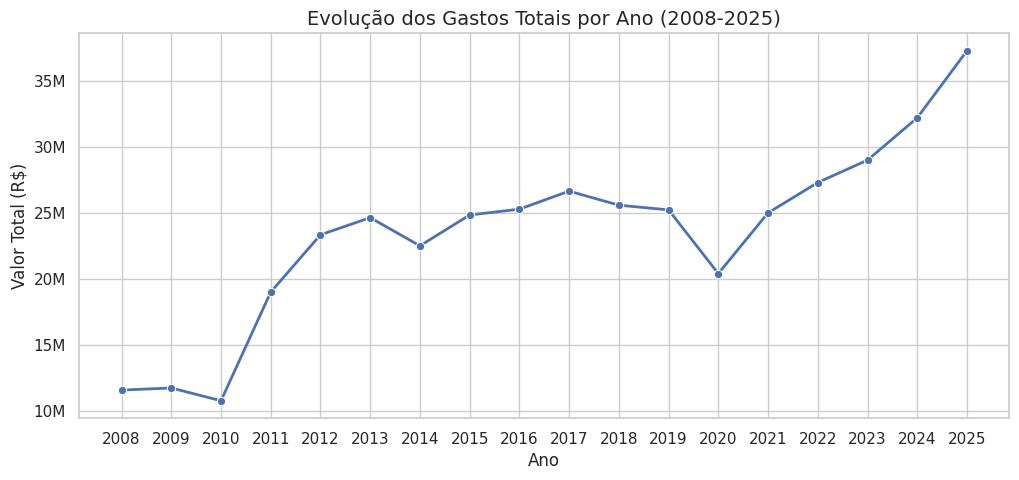

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

gastos_por_ano = despesas.groupby('ANO')['VALOR_REEMBOLSADO'].sum().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=gastos_por_ano, x='ANO', y='VALOR_REEMBOLSADO', marker='o', color='b', linewidth=2)
plt.title('Evolução dos Gastos Totais por Ano (2008-2025)', fontsize=14)
plt.xlabel('Ano')
plt.ylabel('Valor Total (R$)')
plt.xticks(gastos_por_ano['ANO'])
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

A série histórica revela uma tendência geral de crescimento no valor total reembolsado aos senadores ao longo dos anos. Nota-se uma quebra acentuada no ano de 2020, o que pode está diretamente correlacionado com a pandemia de COVID-19, período em que as deslocações aéreas e as atividades parlamentares presenciais foram reduzidas. Contudo, após este evento, a curva retoma uma trajetória de subida expressiva, culminando no pico máximo de despesas registado no ano de 2025.

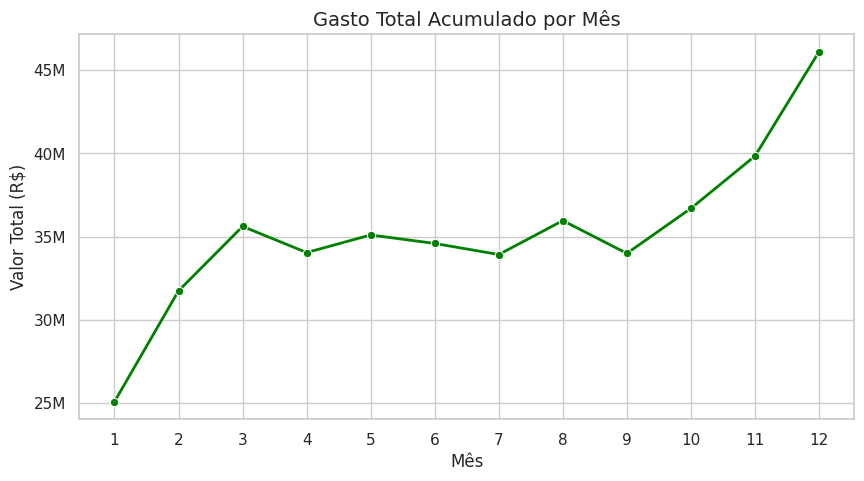

In [35]:
gastos_por_mes = despesas.groupby('MÊS')['VALOR_REEMBOLSADO'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=gastos_por_mes, x='MÊS', y='VALOR_REEMBOLSADO', marker='o', color='green', linewidth=2)
plt.title('Gasto Total Acumulado por Mês', fontsize=14)
plt.xlabel('Mês')
plt.ylabel('Valor Total (R$)')
plt.xticks(range(1, 13))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

A análise da sazonalidade demonstra que os gastos se mantêm num patamar de estabilidade durante a maior parte do ano (entre março e outubro). No entanto, regista-se um pico extremo e contínuo nos meses de novembro e dezembro. Este comportamento evidencia um padrão claro de esgotamento de recursos no final do exercício financeiro, sugerindo que os gabinetes parlamentares aceleram a utilização do saldo remanescente das suas quotas anuais antes que estas expirem na viragem do ano, aliado possivelmente ao processamento de faturas acumuladas.

### Distribuição das despesas por categoria

###

/tmp/ipykernel_27534/571467703.py:13: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


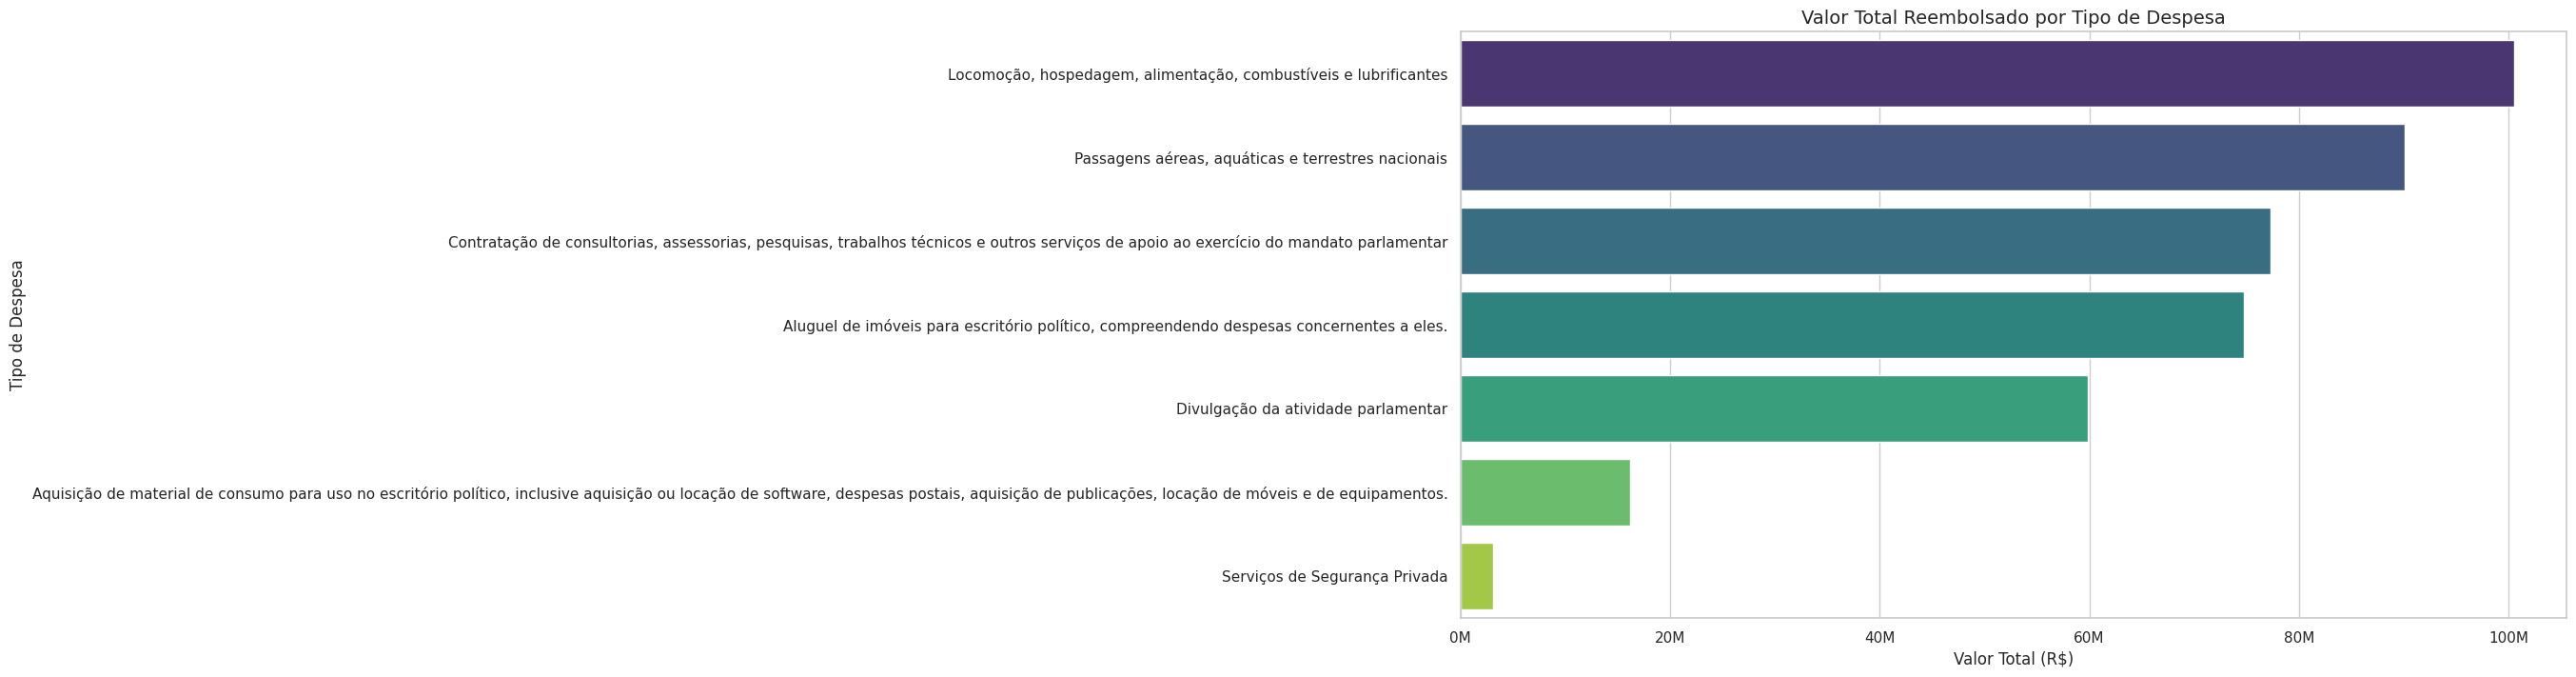

In [36]:
gastos_categoria = despesas.groupby('TIPO_DESPESA_PADRONIZADO').agg(
    Valor_Total=('VALOR_REEMBOLSADO', 'sum'),
    Quantidade=('ID', 'count')
).reset_index()

gastos_categoria_valor = gastos_categoria.sort_values('Valor_Total', ascending=False)
plt.figure(figsize=(15, 8))
sns.barplot(data=gastos_categoria_valor, y='TIPO_DESPESA_PADRONIZADO', x='Valor_Total', hue='TIPO_DESPESA_PADRONIZADO', palette='viridis', legend =False)
plt.title('Valor Total Reembolsado por Tipo de Despesa', fontsize=14)
plt.xlabel('Valor Total (R$)')
plt.ylabel('Tipo de Despesa')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.tight_layout()
plt.show()

A distribuição dos reembolsos evidencia que a maior fatia dos recursos da quota parlamentar é absorvida por despesas logísticas e de mobilidade. A categoria "Locomoção, hospedagem, alimentação, combustíveis e lubrificantes" lidera de forma isolada os gastos, sendo imediatamente seguida pelas despesas com "Passagens aéreas, aquáticas e terrestres nacionais". A "Contratação de consultorias e assessorias" e o "Aluguel de imóveis para escritório político" ocupam o terceiro e quarto lugares, respetivamente. Este cenário indica que a manutenção operacional básica dos gabinetes e as deslocações contínuas dos senadores representam o principal ónus financeiro da atividade parlamentar, superando significativamente os gastos diretos com a divulgação da própria atividade

/tmp/ipykernel_27534/1764147682.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


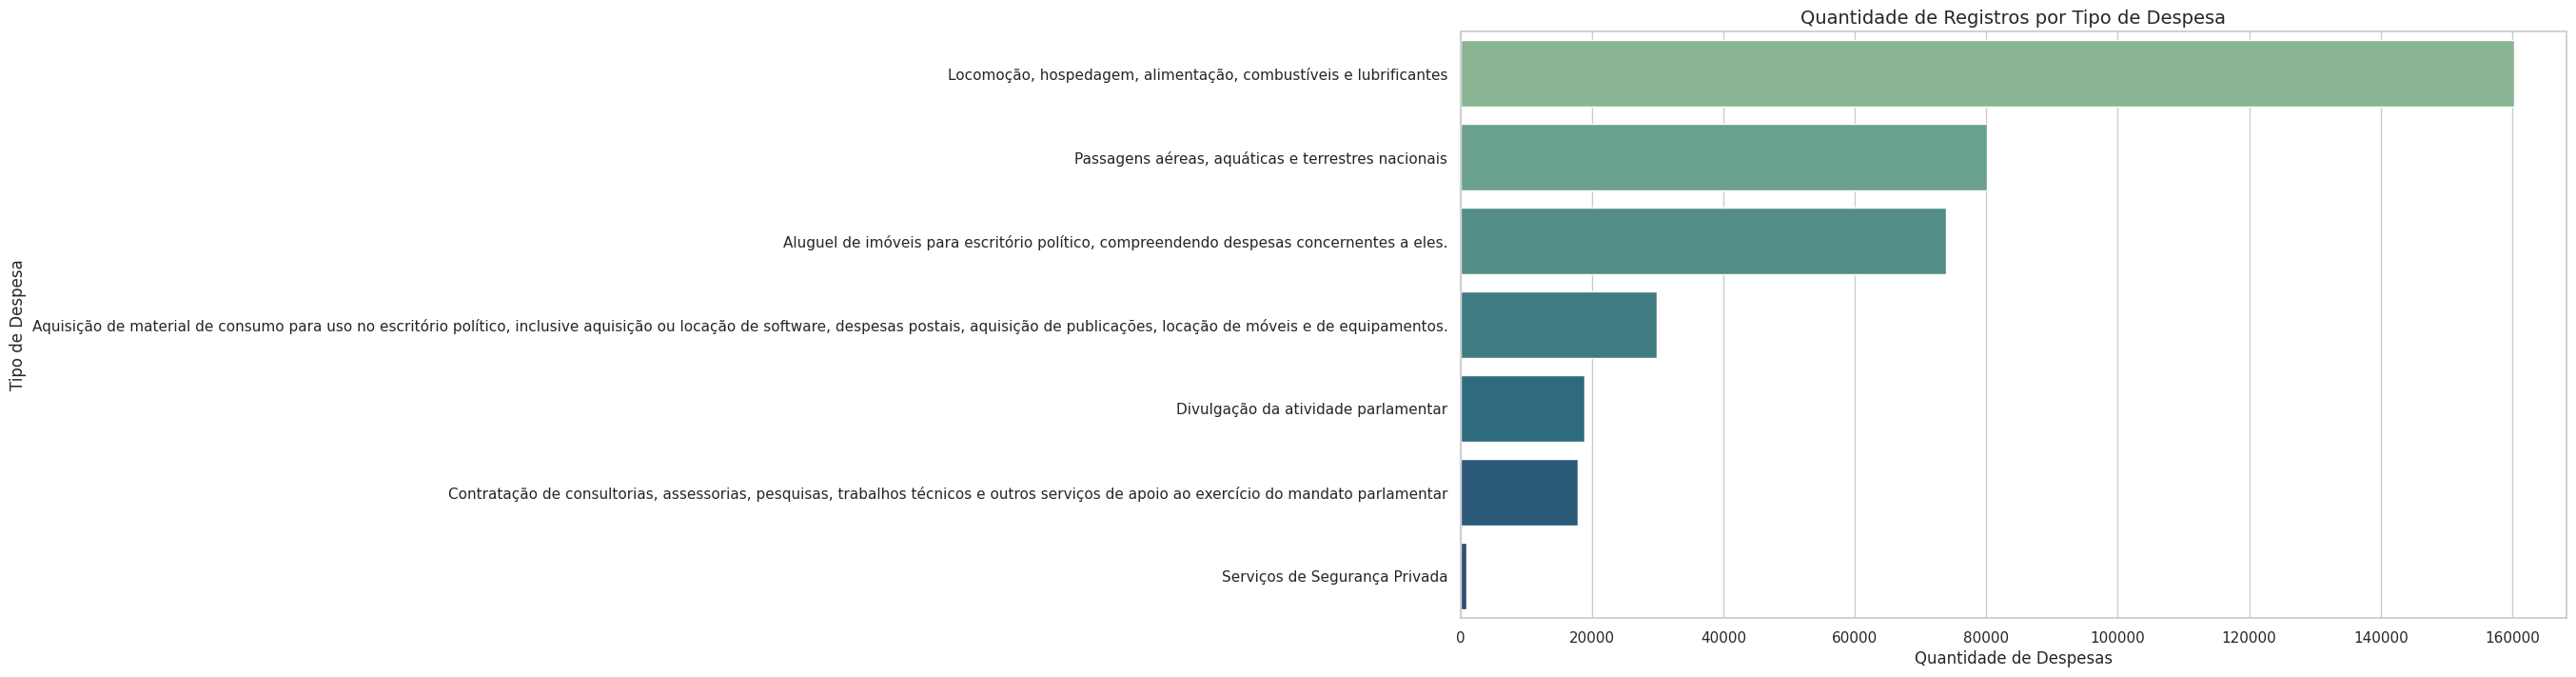

In [37]:
gastos_categoria_qtd = gastos_categoria.sort_values('Quantidade', ascending=False)
plt.figure(figsize=(15, 8))
sns.barplot(data=gastos_categoria_qtd, y='TIPO_DESPESA_PADRONIZADO', x='Quantidade', hue='TIPO_DESPESA_PADRONIZADO', palette='crest', legend = False)
plt.title('Quantidade de Registros por Tipo de Despesa', fontsize=14)
plt.xlabel('Quantidade de Despesas')
plt.ylabel('Tipo de Despesa')
plt.tight_layout()
plt.show()

A análise do volume de documentos fiscais corrobora a predominância dos gastos operacionais e logísticos na rotina dos gabinetes. A categoria de "Locomoção, hospedagem, alimentação, combustíveis e lubrificantes" lidera de forma isolada em quantidade de transações.

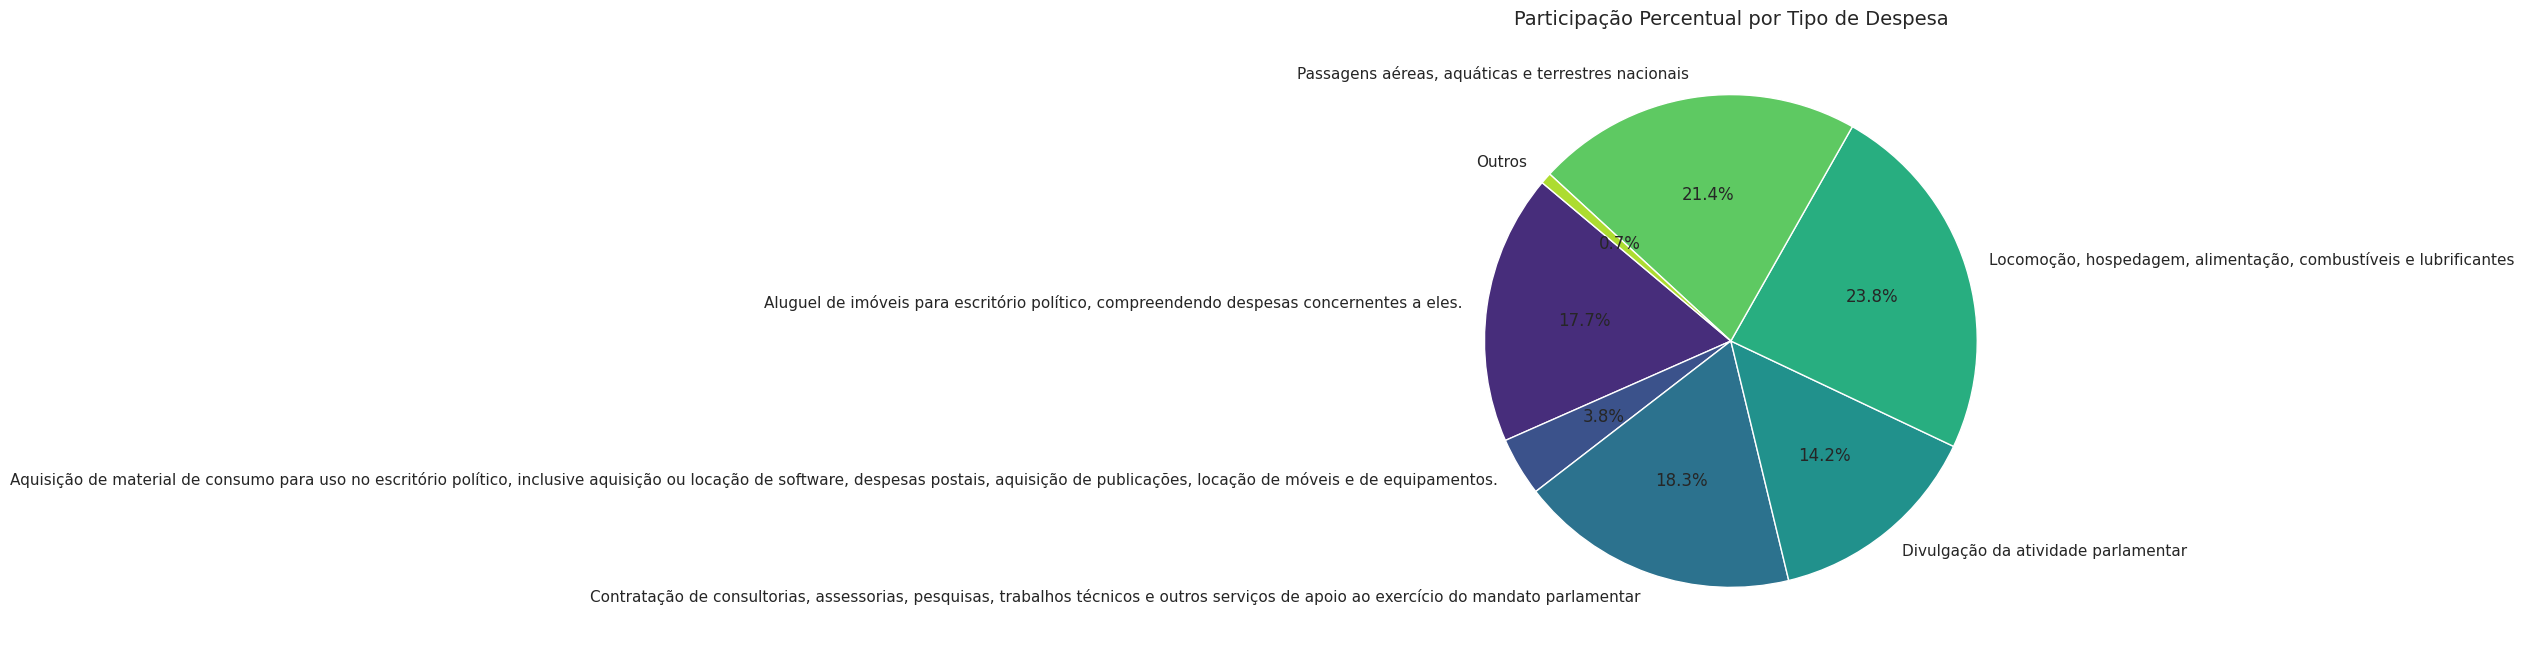

In [38]:
gastos_categoria['Percentual'] = (gastos_categoria['Valor_Total'] / gastos_categoria['Valor_Total'].sum()) * 100
cat_principais = gastos_categoria[gastos_categoria['Percentual'] >= 2]
cat_outros = pd.DataFrame([{'TIPO_DESPESA_PADRONIZADO': 'Outros', 'Percentual': gastos_categoria[gastos_categoria['Percentual'] < 2]['Percentual'].sum()}])
cat_pizza = pd.concat([cat_principais, cat_outros])
plt.figure(figsize=(10, 8))
cores = sns.color_palette('viridis', len(cat_pizza))
plt.pie(cat_pizza['Percentual'], labels=cat_pizza['TIPO_DESPESA_PADRONIZADO'], autopct='%1.1f%%', startangle=140, colors=cores)
plt.title('Participação Percentual por Tipo de Despesa', fontsize=14)
plt.show()

A distribuição percentual confirma que a logística e mobilidade dominam o orçamento. Quase metade da quota parlamentar é consumida apenas pelas rubricas de "Locomoção, hospedagem e alimentação" (23,8%) e "Passagens aéreas" (21,4%).

### Distribuição dos gastos entre os senadores

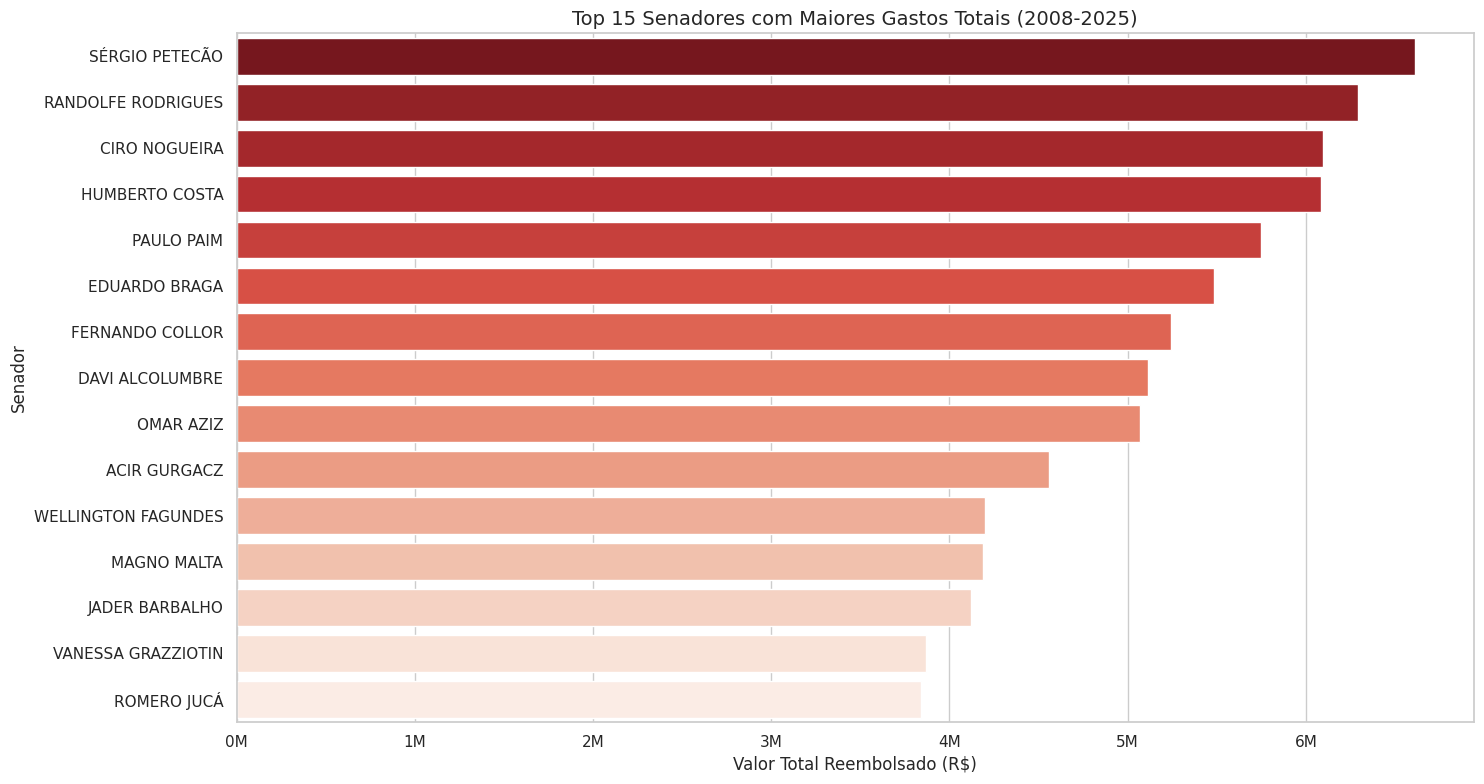

In [39]:
gastos_senador = despesas.groupby('NOME_SENADOR_PADRONIZADO').agg(
    Valor_Total=('VALOR_REEMBOLSADO', 'sum'),
    Quantidade=('ID', 'count')
).reset_index()

top_senadores = gastos_senador.sort_values('Valor_Total', ascending=False).head(15)
plt.figure(figsize=(15, 8))
sns.barplot(data=top_senadores, y='NOME_SENADOR_PADRONIZADO', x='Valor_Total', hue= 'NOME_SENADOR_PADRONIZADO', palette='Reds_r', legend=False)
plt.title('Top 15 Senadores com Maiores Gastos Totais (2008-2025)', fontsize=14)
plt.xlabel('Valor Total Reembolsado (R$)')
plt.ylabel('Senador')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.tight_layout()
plt.show()

O ranking dos 15 senadores com maiores gastos acumulados entre 2008 e 2025 é liderado por Sérgio Petecão, que ultrapassa a marca dos 6 milhões de reais. Logo a seguir surgem Randolfe Rodrigues, Ciro Nogueira e Humberto Costa, também com valores muito elevados.

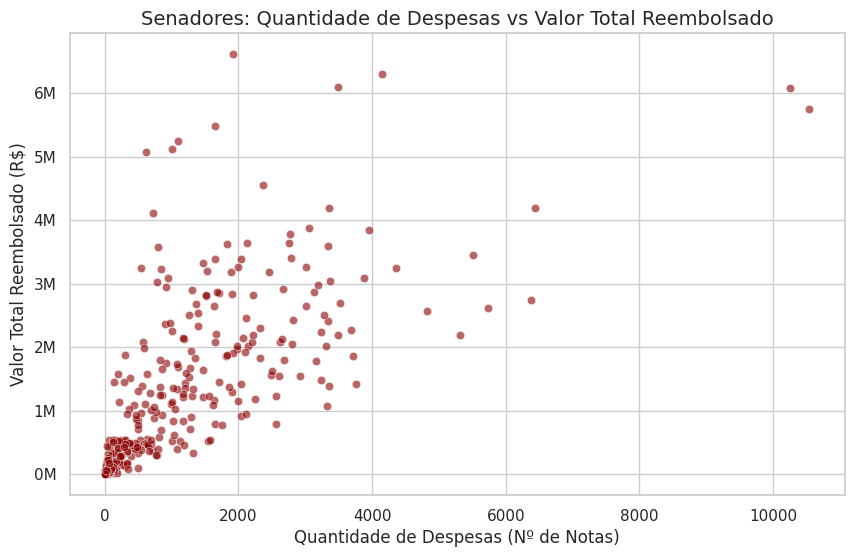

In [40]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=gastos_senador, x='Quantidade', y='Valor_Total', alpha=0.6, color='darkred')
plt.title('Senadores: Quantidade de Despesas vs Valor Total Reembolsado', fontsize=14)
plt.xlabel('Quantidade de Despesas (Nº de Notas)')
plt.ylabel('Valor Total Reembolsado (R$)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

O gráfico de dispersão evidencia a correlação entre o volume de notas emitidas e o valor total gasto por senador. A grande maioria dos parlamentares concentra-se na base do eixo, apresentando um perfil de até 4.000 despesas e gastos acumulados inferiores a 4 milhões de reais. No entanto, o cruzamento revela dois comportamentos atípicos que tracionam os custos para cima: senadores que atingem valores totais próximos aos 6 milhões de reais com relativamente poucas notas, o que indica o predomínio de despesas de alto valor unitário e, no extremo direito, parlamentares com mais de 10.000 transações. demonstrando o uso massivo e contínuo da cota para pequenas despesas rotineiras de baixo valor que, somadas, também esgotam o limite do orçamento.


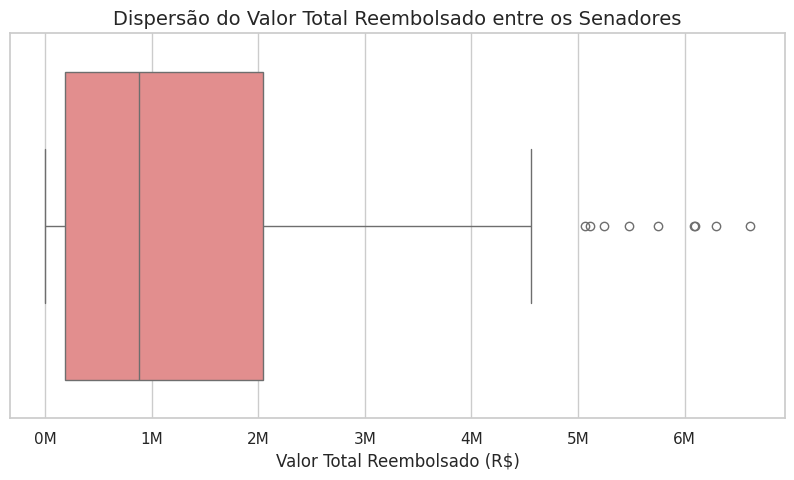

--- Estatísticas de Dispersão: Valor Total por Senador ---
Média de gastos:   R$ 1,296,402.36
Mediana de gastos: R$ 877,736.73
Desvio Padrão:     R$ 1,335,116.08
Maior valor:       R$ 6,611,952.03


In [41]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=gastos_senador['Valor_Total'], color='lightcoral')
plt.title('Dispersão do Valor Total Reembolsado entre os Senadores', fontsize=14)
plt.xlabel('Valor Total Reembolsado (R$)')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

media_senador = gastos_senador['Valor_Total'].mean()
mediana_senador = gastos_senador['Valor_Total'].median()
desvio_padrao_senador = gastos_senador['Valor_Total'].std()
maximo_senador = gastos_senador['Valor_Total'].max()

print("--- Estatísticas de Dispersão: Valor Total por Senador ---")
print(f"Média de gastos:   R$ {media_senador:,.2f}")
print(f"Mediana de gastos: R$ {mediana_senador:,.2f}")
print(f"Desvio Padrão:     R$ {desvio_padrao_senador:,.2f}")
print(f"Maior valor:       R$ {maximo_senador:,.2f}")

A análise da dispersão revela uma assimetria nos gastos totais acumulados por senador. Enquanto a mediana se situa nos 877.736,73, a média é elevada para 1.296.402,36 devido à influência de valores atípicos (outliers) visíveis à direita do boxplot. O desvio padrão de 1.335.116,08, que chega a ser superior à própria média, associado a um limite máximo que atinge os 6.611.952,03, confirmam a existência de uma enorme disparidade na forma como diferentes parlamentares utilizam os recursos da cota ao longo dos seus mandatos.

### Comparação dos gastos por UF

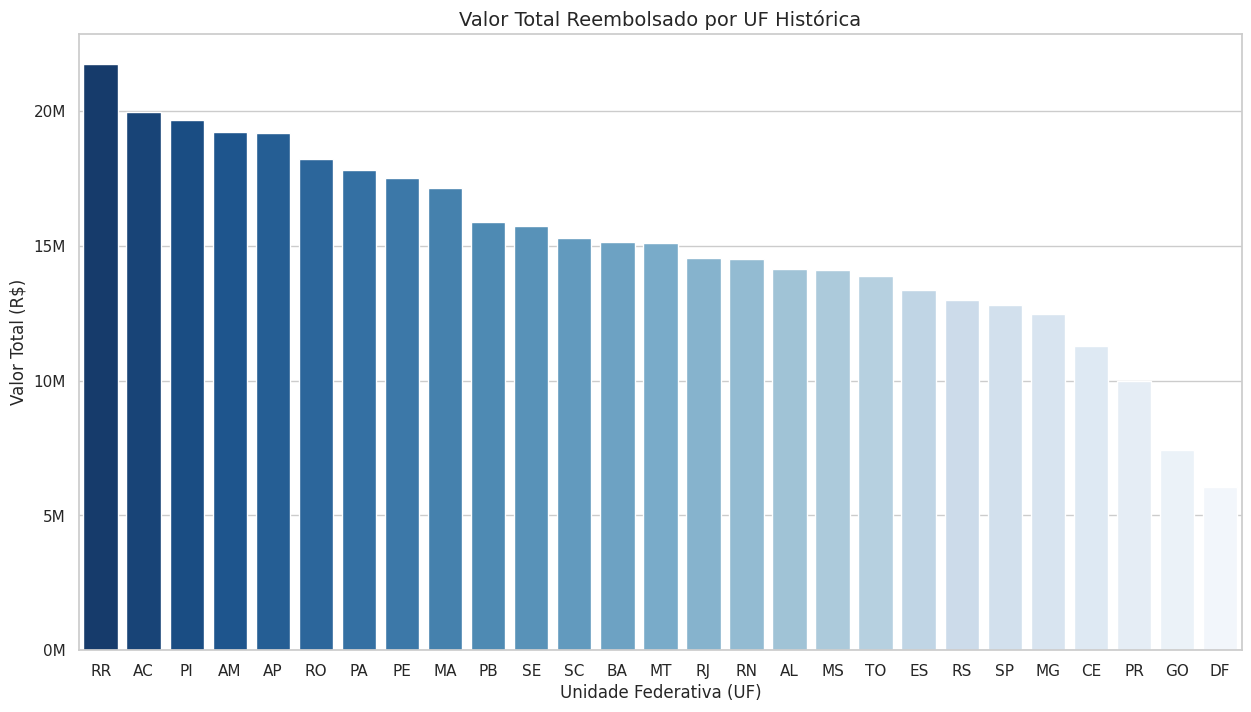

In [42]:
despesas_uf = despesas.dropna(subset=['UF_HISTORICA']).copy()
gastos_uf = despesas_uf.groupby('UF_HISTORICA').agg(
    Valor_Total=('VALOR_REEMBOLSADO', 'sum'),
    Quantidade=('ID', 'count')
).reset_index()

gastos_uf['UF_HISTORICA'] = gastos_uf['UF_HISTORICA'].astype(str)
gastos_uf['Valor_Total'] = gastos_uf['Valor_Total'].astype(float)
gastos_uf_valor = gastos_uf.sort_values('Valor_Total', ascending=False)

plt.figure(figsize=(15, 8))
sns.barplot(data=gastos_uf_valor, x='UF_HISTORICA', y='Valor_Total', hue='UF_HISTORICA', palette='Blues_r', legend=False)
plt.title('Valor Total Reembolsado por UF Histórica', fontsize=14)
plt.xlabel('Unidade Federativa (UF)')
plt.ylabel('Valor Total (R$)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

O gráfico ilustra o montante total reembolsado por cada Unidade Federativa entre 2008 e 2025. Destaca-se a liderança de Roraima (RR), que ultrapassa os 20 milhões de reais. Os estados do Acre (AC), Piauí (PI), Amazonas (AM) e Amapá (AP) também figuram no topo, todos com valores próximos ou superiores aos 15 milhões. Esta distribuição confirma que a distância geográfica em relação a Brasília é um fator determinante nos custos. Estados da região Norte e Nordeste lideram os gastos, influenciados pelo preço elevado das passagens aéreas e pela logística complexa. Em contraste, o Distrito Federal (DF) e o estado de Goiás (GO), mais próximos da capital, apresentam os menores volumes de despesas acumuladas.

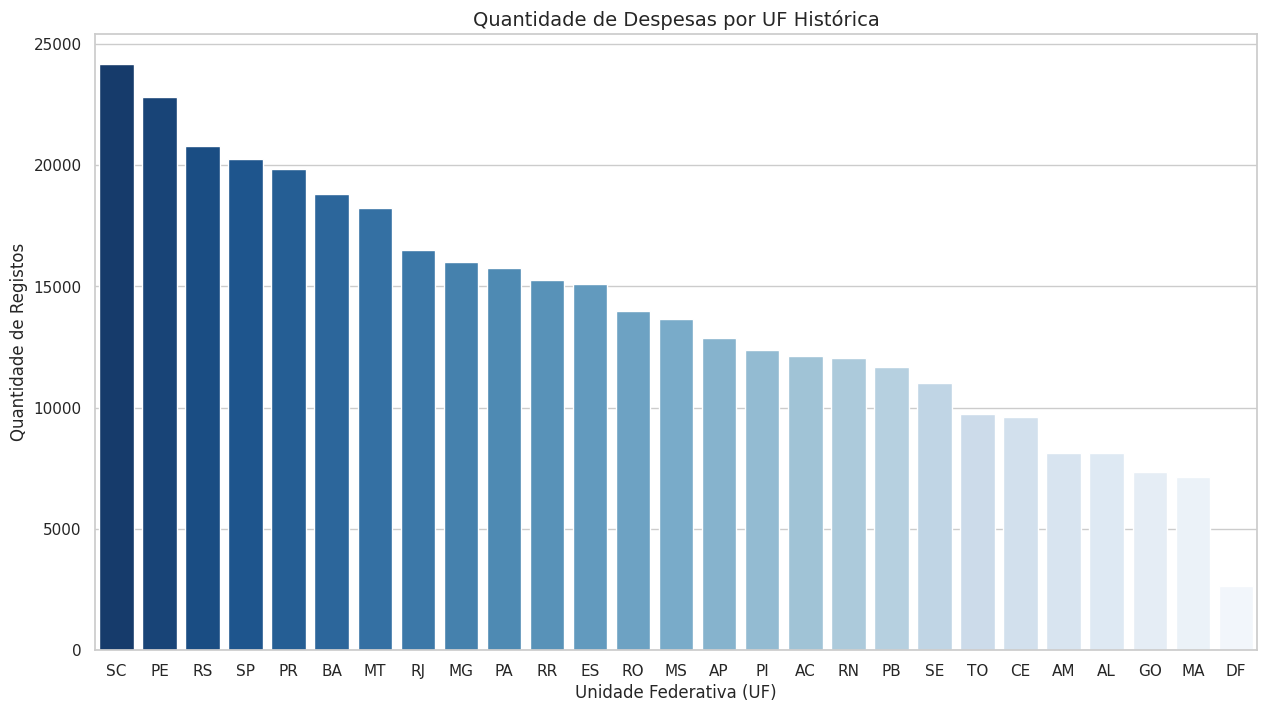

In [43]:
gastos_uf_qtd = gastos_uf.sort_values('Quantidade', ascending=False)
plt.figure(figsize=(15, 8))
sns.barplot(data=gastos_uf_qtd, x='UF_HISTORICA', y='Quantidade', hue='UF_HISTORICA', palette='Blues_r', legend=False)
plt.title('Quantidade de Despesas por UF Histórica', fontsize=14)
plt.xlabel('Unidade Federativa (UF)')
plt.ylabel('Quantidade de Registos')
plt.show()

Ao analisar o volume de transações por estado, nota-se uma inversão face ao gráfico de valores totais. Santa Catarina (SC) lidera o número de despesas com mais de 20.000 registos, seguida por Pernambuco (PE), Rio Grande do Sul (RS), São Paulo (SP) e Paraná (PR). O Distrito Federal (DF) e o Maranhão (MA) mantêm-se nos lugares mais baixos. Este contraste sugere que os estados do Sul e Sudeste, embora não sejam os que mais gastam em valor absoluto, registam uma frequência muito maior na utilização da cota, provavelmente em despesas de menor valor.

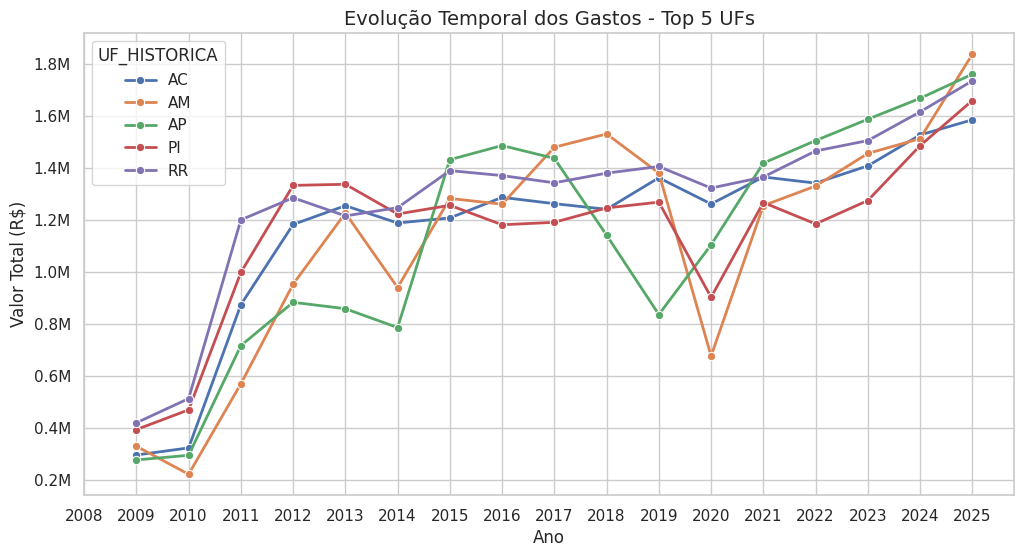

In [59]:
top_5_ufs = gastos_uf_valor.head(5)['UF_HISTORICA']
evolucao_uf = despesas_uf[despesas_uf['UF_HISTORICA'].isin(top_5_ufs)].groupby(['ANO', 'UF_HISTORICA'])['VALOR_REEMBOLSADO'].sum().reset_index()
evolucao_uf['UF_HISTORICA'] = evolucao_uf['UF_HISTORICA'].astype(str)
evolucao_uf['VALOR_REEMBOLSADO'] = evolucao_uf['VALOR_REEMBOLSADO'].astype(float)
evolucao_uf['ANO'] = evolucao_uf['ANO'].astype(int)

plt.figure(figsize=(12, 6))
sns.lineplot(data=evolucao_uf, x='ANO', y='VALOR_REEMBOLSADO', hue='UF_HISTORICA', marker='o', linewidth=2)
plt.title('Evolução Temporal dos Gastos - Top 5 UFs', fontsize=14)
plt.xlabel('Ano')
plt.ylabel('Valor Total (R$)')
plt.xticks(range(2008, 2026))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x/1e6:.1f}M"))
plt.show()

A evolução temporal revela uma trajetória ascendente nos gastos das cinco Unidades Federativas de maior custo entre 2008 e 2025. Este padrão de crescimento contínuo é subitamente interrompido por uma quebra acentuada em 2020, o que reflete o impacto direto das restrições de mobilidade e da adoção do trabalho remoto durante a pandemia de COVID-19. No entanto, a partir de 2021, regista-se uma rápida retoma da tendência de subida, culminando com todos os estados do topo a atingirem os seus picos máximos históricos de despesa no final do período analisado.

### Comparação dos gastos por partido político

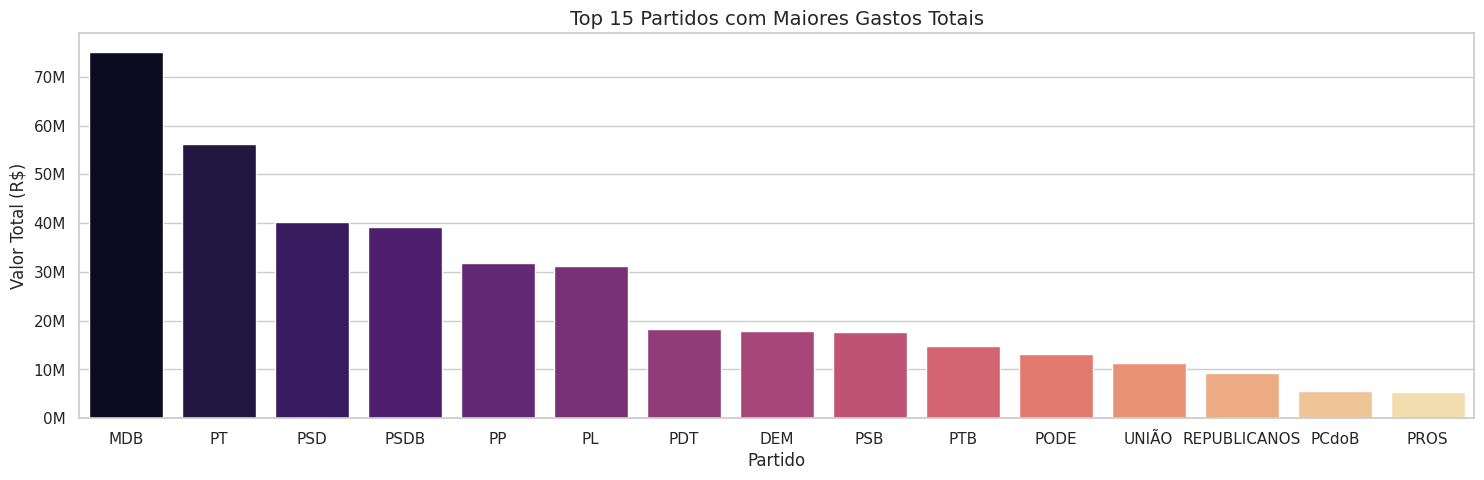

In [49]:
despesas_partido = despesas.dropna(subset=['PARTIDO_HISTORICO'])
gastos_partido = despesas_partido.groupby('PARTIDO_HISTORICO').agg(
    Valor_Total=('VALOR_REEMBOLSADO', 'sum'),
    Quantidade=('ID', 'count')
).reset_index()

plt.figure(figsize=(18, 5))
sns.barplot(data=gastos_partido.sort_values('Valor_Total', ascending=False).head(15), x='PARTIDO_HISTORICO', y='Valor_Total', hue='PARTIDO_HISTORICO', palette='magma', legend=False)
plt.title('Top 15 Partidos com Maiores Gastos Totais', fontsize=14)
plt.xlabel('Partido')
plt.ylabel('Valor Total (R$)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

A análise do volume financeiro por partido político revela uma forte concentração de gastos nas legendas mais tradicionais. O MDB lidera a tabela de forma destacada, ultrapassando os 70 milhões de reais em reembolsos acumulados, seguido pelo PT, que supera a marca dos 50 milhões. O PSD e o PSDB surgem logo a seguir no ranking, apresentando valores muito próximos dos 40 milhões de reais. Esta distribuição reflete diretamente a dimensão histórica das bancadas partidárias. Como estes partidos elegeram e mantiveram o maior número de senadores no ativo ao longo de todo o período analisado (2008 a 2025), o avolumar das suas despesas em termos absolutos é uma consequência natural da sua elevada representatividade no Senado Federal.

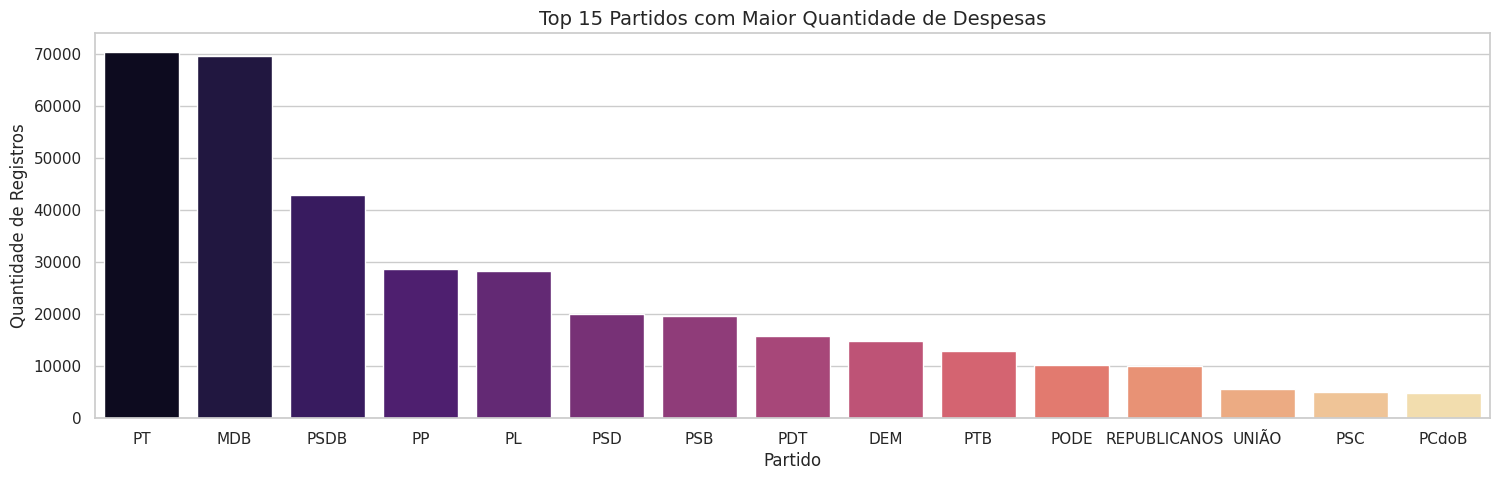

In [52]:
plt.figure(figsize=(18, 5))
sns.barplot(data=gastos_partido.sort_values('Quantidade', ascending=False).head(15), x='PARTIDO_HISTORICO', y='Quantidade', hue='PARTIDO_HISTORICO', palette='magma', legend=False)
plt.title('Top 15 Partidos com Maior Quantidade de Despesas', fontsize=14)
plt.xlabel('Partido')
plt.ylabel('Quantidade de Registros')
plt.show()

A análise da quantidade de transações por partido reforça o domínio das legendas com maior representação histórica. O PT e o MDB lideram a tabela de forma destacada, registando ambos um volume muito próximo das 70.000 despesas acumuladas. O PSDB surge num distante terceiro lugar, com pouco mais de 40.000 ocorrências, seguido pelo PP e pelo PL. A forte presença do PT no topo do número de notas emitidas, apesar de ocupar o segundo lugar no valor financeiro total (como visto no tópico anterior), sugere uma tendência desta bancada parlamentar para um maior fracionamento dos gastos, traduzindo-se numa utilização mais frequente da quota para despesas de menor valor unitário.

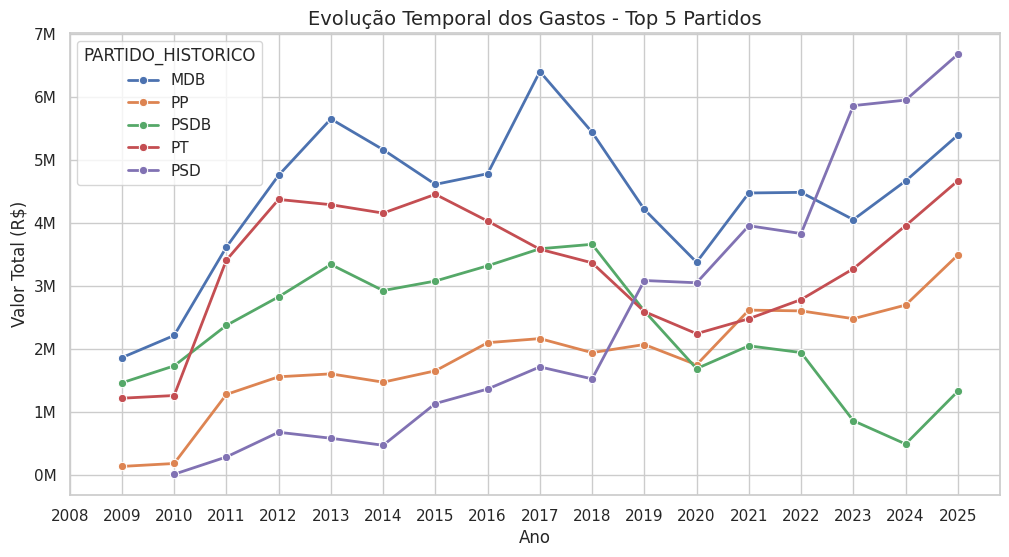

In [53]:
top_5_partidos = gastos_partido.sort_values('Valor_Total', ascending=False).head(5)['PARTIDO_HISTORICO']
evolucao_partido = despesas_partido[despesas_partido['PARTIDO_HISTORICO'].isin(top_5_partidos)].groupby(['ANO', 'PARTIDO_HISTORICO'])['VALOR_REEMBOLSADO'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=evolucao_partido, x='ANO', y='VALOR_REEMBOLSADO', hue='PARTIDO_HISTORICO', marker='o', linewidth=2)
plt.title('Evolução Temporal dos Gastos - Top 5 Partidos', fontsize=14)
plt.xlabel('Ano')
plt.ylabel('Valor Total (R$)')
plt.xticks(range(2008, 2026))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))
plt.show()

A evolução temporal dos gastos reflete as reconfigurações de força política no Senado. O MDB dominou historicamente o volume de reembolsos, mantendo-se no topo durante a maior parte do período analisado. No entanto, o cenário recente (2023-2025) evidencia a forte ascensão do PT e do PSD, que registra um crescimento expressivo e acaba assumindo a liderança da despesa na reta final. Em sentido inverso, destaca-se a queda abrupta e contínua do PSDB a partir de 2018, cujos gastos caem drasticamente até se aproximarem do zero em 2024 e 2025, o que espelha a severa perda de senadores da legenda nas últimas eleições. À semelhança da análise por estados, é também visível uma quebra transversal em todas as linhas no ano de 2020, evidenciando o impacto das restrições da pandemia na rotina parlamentar.

### Análise dos reembolsos

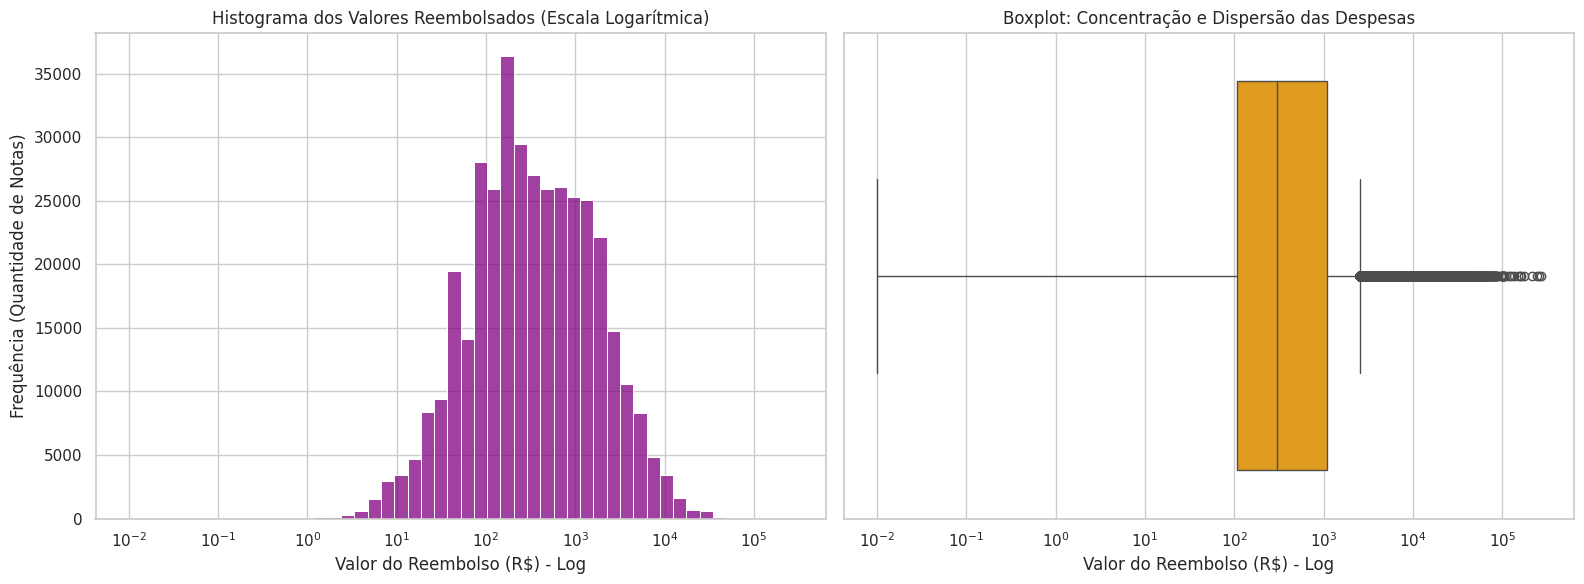

In [55]:
despesas_positivas = despesas[despesas['VALOR_REEMBOLSADO'] > 0].copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(despesas_positivas['VALOR_REEMBOLSADO'], bins=50, log_scale=True, ax=ax1, color='purple')
ax1.set_title('Histograma dos Valores Reembolsados (Escala Logarítmica)')
ax1.set_xlabel('Valor do Reembolso (R$) - Log')
ax1.set_ylabel('Frequência (Quantidade de Notas)')

sns.boxplot(x=despesas_positivas['VALOR_REEMBOLSADO'], ax=ax2, color='orange')
ax2.set_xscale('log')
ax2.set_title('Boxplot: Concentração e Dispersão das Despesas')
ax2.set_xlabel('Valor do Reembolso (R$) - Log')

plt.tight_layout()
plt.show()

A análise do histograma em escala logarítmica evidencia que a esmagadora maioria dos reembolsos se concentra em valores de pequena a média dimensão. O pico de frequência (a moda) situa-se na faixa dos 100 reais (visível no eixo no valor de $10^2$), com o grande volume de notas a oscilar entre os 10 e os 1.000 reais. A longa cauda que se estende para a direita, alcançando a marca dos 100.000 reais ($10^5$), comprova a existência de despesas esporádicas de altíssimo valor que distorcem a média geral do Senado.

O boxplot reforça visualmente a assimetria dos dados. A caixa central, que engloba os 50% das despesas mais comuns (intervalo interquartil), é bastante compacta e restrita aos valores mais baixos do eixo. O aspeto mais marcante deste gráfico é a densa e extensa linha de outliers à direita (pontos pretos), demonstrando que as despesas de valor extremo (na ordem das dezenas e centenas de milhares de reais) são abundantes na base de dados. Estes outliers justificam os totais milionários acumulados por certos senadores, mesmo com uma quantidade reduzida de transações.

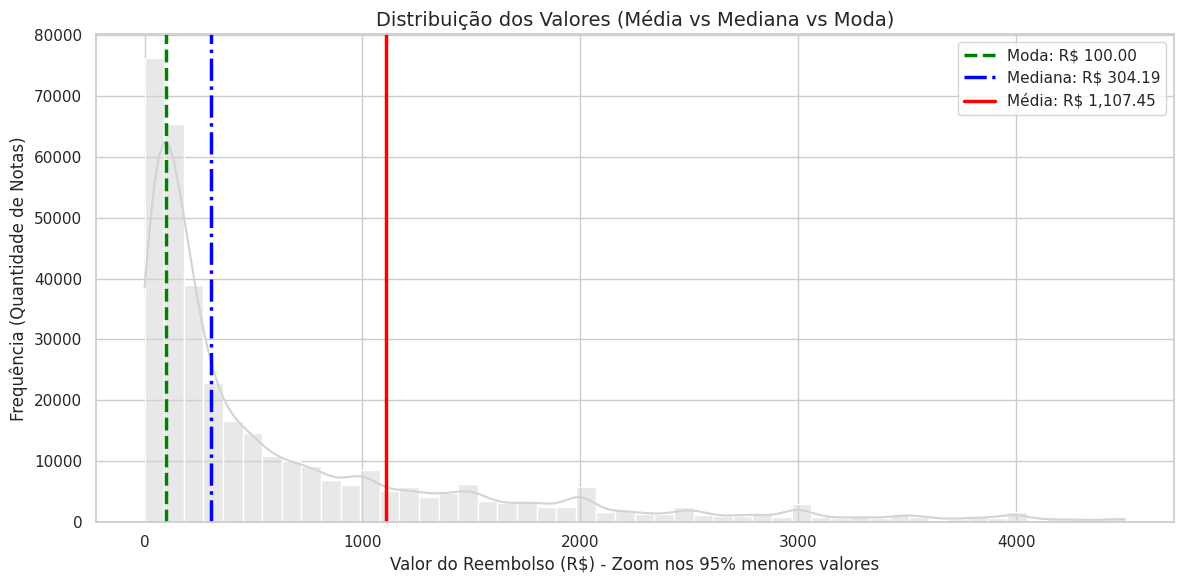

In [58]:
media = despesas_positivas['VALOR_REEMBOLSADO'].mean()
mediana = despesas_positivas['VALOR_REEMBOLSADO'].median()
moda = despesas_positivas['VALOR_REEMBOLSADO'].mode()[0]

limite_visual = despesas_positivas['VALOR_REEMBOLSADO'].quantile(0.95)
dados_zoom = despesas_positivas[despesas_positivas['VALOR_REEMBOLSADO'] <= limite_visual]

plt.figure(figsize=(12, 6))
sns.histplot(dados_zoom['VALOR_REEMBOLSADO'], bins=50, color='lightgray', kde=True)

plt.axvline(moda, color='green', linestyle='--', linewidth=2.5, label=f'Moda: R$ {moda:,.2f}')
plt.axvline(mediana, color='blue', linestyle='-.', linewidth=2.5, label=f'Mediana: R$ {mediana:,.2f}')
plt.axvline(media, color='red', linestyle='-', linewidth=2.5, label=f'Média: R$ {media:,.2f}')
plt.title('Distribuição dos Valores (Média vs Mediana vs Moda)', fontsize=14)
plt.xlabel('Valor do Reembolso (R$) - Zoom nos 95% menores valores')
plt.ylabel('Frequência (Quantidade de Notas)')
plt.legend()
plt.tight_layout()
plt.show()

A comparação entre as medidas de tendência central ilustra na perfeição a forte assimetria à direita na distribuição dos gastos parlamentares. A concentração das transações em valores baixos é evidenciada pela moda de 100,00 e pela mediana de 304,19, o que revela que pelo menos metade de todos os reembolsos solicitados não ultrapassa este último patamar. Em contrapartida, a média aritmética (R$ 1.107,45) encontra-se significativamente deslocada para a direita. Este desvio expressivo da linha vermelha comprova o peso matemático e financeiro desproporcional que os outliers de alto valor (os 5% de faturas extremas que foram omitidas neste recorte visual para facilitar a leitura) exercem sobre o custo total do Senado, puxando a média para quase o triplo do valor mediano.

###

## Primeiras Respostas

Com base nas análises e nos padrões extraídos dos gráficos, temos as primeiras respostas consolidadas para as perguntas da pesquisa:

 - Evolução e Períodos de Maiores Gastos: Historicamente, os gastos apresentam uma trajetória de crescimento contínuo, impulsionada pelo acúmulo de despesas ao longo dos mandatos. A principal anomalia temporal ocorreu em 2020, que registrou uma queda abrupta e generalizada devido às restrições de mobilidade e ao trabalho remoto impostos pela pandemia de COVID-19. A partir de 2021, o padrão de alta foi retomado, com os anos mais recentes (2024-2025) registrando os picos máximos históricos de despesas.

 - Maiores Gastos por Unidade Federativa (UF): Os estados com maiores gastos totais estão fortemente correlacionados com a distância geográfica até a capital federal. Roraima (RR) lidera isoladamente com mais de 20 milhões de reais, seguido por Acre (AC), Piauí (PI), Amazonas (AM) e Amapá (AP). Curiosamente, estados do Sul e Sudeste (como SC, SP, RS e PR) não lideram em valor financeiro, mas concentram o maior volume (quantidade) de notas emitidas, indicando o uso frequente da cota para despesas de menor valor.

 - Gastos por Partidos Políticos: O MDB lidera de forma destacada o valor total de gastos (ultrapassando os 70 milhões de reais), seguido por PT, PSD e PSDB. Esse alto volume financeiro é um reflexo direto do tamanho histórico de suas bancadas. Na quantidade de transações, PT e MDB lideram empatados com quase 70.000 notas cada. Destaca-se também a reconfiguração política recente: partidos como o PSDB viram seus gastos despencarem quase a zero a partir de 2018 devido à perda de cadeiras, enquanto PT e PSD tiveram um rápido crrscimento.

 - Senadores com Maiores Gastos: O ranking é liderado por Sérgio Petecão (ultrapassando 6 milhões), seguido por Randolfe Rodrigues e Ciro Nogueira. A análise evidenciou que o alto custo de um mandato é ditado por dois fatores principais: longevidade no cargo e origem em estados distantes (Norte/Nordeste). A distribuição é altamente assimétrica, com outliers extremos puxando a média geral (1,29 milhão) para quase o triplo do valor mediano de gastos diários (877 mil).

 - Tipos de Despesas Predominantes: O orçamento é esmagadoramente consumido por logística e mobilidade. A categoria "Locomoção, hospedagem, alimentação, combustíveis e lubrificantes" (22,8%) e as "Passagens aéreas, aquáticas e terrestres" (21,4%) somam, sozinhas, quase metade de todo o valor reembolsado. A manutenção da infraestrutura de mandato vem a seguir, com "Divulgação da atividade parlamentar" (14,2%) e "Aluguel de imóveis" (10,7%).